# 03 · Washing-machine disaggregation model

**Input:** whole-house aggregate power, using readings at or before each minute. **Target:** washing-machine power in watts, 1-minute resolution, official cleaned REFIT.

Models are trained by `scripts/run_experiments.py`, and this notebook evaluates the saved test predictions. Every figure and table uses evaluation data only.

> **Scope of this notebook.** It evaluates the past-only baseline models. Here, "final model" and "no future data" refer to that baseline, saved as `outputs/models/final_model.joblib`. The submission's final model is the look-ahead model in `src/lookahead.py`, trained by `scripts/run_final_model.py` and evaluated by `scripts/evaluate_final_model.py`. Its results are in `RESULTS.md`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from src import config as cfg
from src import visualization as viz

viz.apply_style()
pd.set_option("display.max_columns", 40, "display.width", 200, "display.max_colwidth", 70)
for folder in (cfg.FIGURES, cfg.METRICS, cfg.PREDICTIONS):
    folder.mkdir(parents=True, exist_ok=True)

import gc
import joblib
from scipy import stats
from sklearn.inspection import permutation_importance

from src.cycle_detection import detect_events
from src.data_loader import eligible_houses, parse_readme, read_clean_csv, wm_channel
from src.evaluation import chance_event_metrics, conditional_mae, energy_metrics, evaluate, evaluate_by_house, event_energy_table, event_metrics, onoff_metrics, regression_metrics
from src.feature_engineering import build_dataset, make_features, to_resolution
from src.modeling import load_predictions, selected_methods, temporal_split
from src.preprocessing import clean_file_true_utc, prepare_clean_house

HOUSES = eligible_houses()
print("Houses:", HOUSES)

Houses: [2, 5, 6, 7, 10, 13, 15, 16, 17, 19, 20]


## 1. Validation design

**Primary: leave one house out (LOHO).** A utility would apply the model to homes it has no appliance data for, so that is the question to test. Each house is tested by a model trained only on the other ten.

**Validation inside the training homes.** In each fold, two training houses are held back to pick the ON/OFF threshold and to choose between models. The test house plays no part in either.

**Secondary: temporal split.** The first 70% of each home trains and the last 30% tests. This answers a different question: how well does it do on the future of homes it has already seen?

**Hyperparameters are fixed in advance**, so no search can leak test information.

In [2]:
periods = []
loho_rf, thresholds_rf = load_predictions("loho", "random_forest")
temporal_rf, thresholds_temporal = load_predictions("temporal", "random_forest")
for house in HOUSES:
    all_rows, later = loho_rf[loho_rf["house"] == house], temporal_rf[temporal_rf["house"] == house]
    periods.append({"House": house, "LOHO test start (UTC)": all_rows.index.min().date(), "LOHO test end (UTC)": all_rows.index.max().date(), "LOHO test minutes": len(all_rows),
                    "Temporal test start (UTC)": later.index.min().date(), "Temporal test end (UTC)": later.index.max().date(), "Temporal test minutes": len(later)})
periods = pd.DataFrame(periods).set_index("House")
periods.to_csv(cfg.METRICS / "evaluation_periods.csv")
display(periods)

,LOHO test start (UTC),LOHO test end (UTC),LOHO test minutes,Temporal test start (UTC),Temporal test end (UTC),Temporal test minutes
House,,,,,,
2,2013-09-17,2015-05-28,647077,2014-12-25,2015-05-28,194004
5,2013-09-26,2015-07-06,811164,2014-12-21,2015-07-06,243230
6,2013-11-28,2015-06-28,690417,2014-12-27,2015-06-28,207006
7,2013-11-01,2015-07-08,759467,2014-12-31,2015-07-08,227721
10,2013-11-20,2015-06-10,671596,2015-01-01,2015-06-10,201359
13,2014-01-17,2015-05-31,509317,2015-01-11,2015-05-31,152676
15,2013-12-17,2015-07-08,689908,2015-01-20,2015-07-08,206853
16,2014-01-10,2015-07-08,624529,2015-02-03,2015-07-08,187239
17,2014-03-06,2015-06-19,611971,2015-01-11,2015-06-19,183472


## 2. Can these results be trusted? Leakage and sanity tests

These tests are designed to fail if something is wrong, so a pass means something.

In [3]:
# Test 1: changing the future must not change any feature up to the present.
signal = prepare_clean_house(HOUSES[0])["aggregate"].dropna().iloc[:6000]
signal = signal.reset_index(drop=True)
altered = signal.copy()
altered.iloc[4000:] = altered.iloc[4000:] * 3 + 500
before, after = make_features(signal), make_features(altered)
pd.testing.assert_frame_equal(before.iloc[:4000], after.iloc[:4000])
changed_later = int((before.iloc[4000:].fillna(-1) != after.iloc[4000:].fillna(-1)).any(axis=1).sum())
print(f"PASS 1: features before the change are identical. Control: {changed_later:,} of 2,000 later rows did change.")

# Test 2: the model's inputs contain no target or other appliance channel.
saved = joblib.load(cfg.MODELS / "final_model.joblib")
FEATURES = saved["features"]
banned = [name for name in FEATURES if any(word in name.lower() for word in ("wm", "appliance", "issue", "house", "hour", "day"))]
assert not banned, banned
print(f"PASS 2: all {len(FEATURES)} features come from the aggregate:", FEATURES[:6], "...")

# Test 3: every LOHO prediction file holds only its own test house.
for method in ("random_forest", "hist_gradient_boosting"):
    for path in sorted(cfg.PREDICTIONS.glob(f"loho__{method}__h*.parquet")):
        house = int(path.stem.rsplit("__h", 1)[1])
        assert set(pd.read_parquet(path, columns=["house"])["house"].unique()) == {house}, path.name
print("PASS 3: each test file contains exactly one house.")

# Test 4: the temporal split keeps time order and a gap at the boundary.
index = pd.date_range("2020-01-01", periods=2000, freq="1min")
toy = pd.DataFrame({"house": 1, "wm": 0.0}, index=index)
train, test = temporal_split(toy)
assert train.index.max() < test.index.min()
assert (test.index.min() - train.index.max()) > pd.Timedelta(minutes=120)
print(f"PASS 4: temporal test starts {test.index.min() - train.index.max()} after training ends, longer than the longest 60-minute feature window.")

# Test 5: metrics match a hand calculation from the saved predictions.
check = loho_rf[(loho_rf["house"] == HOUSES[0]) & loho_rf["eval_ok"]]
y, pred = check["wm"].to_numpy(float), check["pred"].to_numpy(float)
hand = np.mean(np.abs(y - pred))
reported = evaluate(check, thresholds_rf[HOUSES[0]], with_events=False)
assert abs(hand - reported["MAE"]) < 1e-6
assert abs(y.sum() / 60_000 - reported["Energy_true_kWh"]) < 1e-6
print(f"PASS 5: hand MAE {hand:.3f} W equals reported {reported['MAE']:.3f} W; energy matches.")

PASS 1: features before the change are identical. Control: 2,000 of 2,000 later rows did change.


PASS 2: all 34 features come from the aggregate: ['agg', 'lag_1', 'diff_1', 'lag_2', 'diff_2', 'lag_5'] ...


PASS 3: each test file contains exactly one house.
PASS 4: temporal test starts 0 days 02:01:00 after training ends, longer than the longest 60-minute feature window.


PASS 5: hand MAE 31.752 W equals reported 31.752 W; energy matches.


## 3. Choosing the model on validation houses only

Random Forest and gradient boosting are compared on the two held-back houses in each fold. The lower validation RMSE wins, a rule fixed before seeing any result. Overall MAE was rejected as the rule because it rewards predicting nothing.

In [4]:
selection = pd.read_csv(cfg.METRICS / "model_selection_inner_validation.csv")
wide = selection.pivot(index="test_house", columns="method", values=["RMSE", "MAE", "MAE_ON"]).round(1)
display(wide)
WINNERS = selected_methods(selection)
print("Winner per fold:", WINNERS)
print("Wins:", pd.Series(WINNERS).value_counts().to_dict())
print("Mean validation RMSE:", selection.groupby("method")["RMSE"].mean().round(1).to_dict())

RMSE                                  MAE                               MAE_ON              
method     hist_gradient_boosting random_forest hist_gradient_boosting random_forest hist_gradient_boosting random_forest
test_house                                                                                                               
2                           121.6         121.9                   22.1          22.0                  323.6         326.5
5                           143.5         146.8                   26.0          27.4                  290.7         293.6
6                           173.8         173.5                   38.3          38.3                  308.5         305.4
7                           172.6         173.9                   38.8          40.2                  277.8         273.9
10                          123.3         123.4                   20.4          20.5                  263.3         265.2
13                           92.1          91.5                   12.8          12.3                  190.3         187.1
15                          157.5         156.8                   28.5          30.0                  349.5         347.4
16                          188.3         192.3                   45.9          47.2                  284.9         288.6
17                          161.5         161.5                   30.1          30.3                  350.4         350.2
19                          155.0         158.0                   31.9          32.5                  277.7         282.7
20                          156.7         157.6                   28.5          28.6                  313.7         309.3

Winner per fold: {2: 'hist_gradient_boosting', 5: 'hist_gradient_boosting', 6: 'random_forest', 7: 'hist_gradient_boosting', 10: 'hist_gradient_boosting', 13: 'random_forest', 15: 'random_forest', 16: 'hist_gradient_boosting', 17: 'hist_gradient_boosting', 19: 'hist_gradient_boosting', 20: 'hist_gradient_boosting'}
Wins: {'hist_gradient_boosting': 8, 'random_forest': 3}
Mean validation RMSE: {'hist_gradient_boosting': 149.6, 'random_forest': 150.7}


**Gradient boosting wins 8 of 11 folds, but only just** (mean validation RMSE 149.6 W against 150.7 W). Several folds differ by under 1 W, so the two models are practically equal here, and the choice is not a meaningful finding. Gradient boosting becomes the final model, and it also trains much faster (about 85 s per fold).

**Why tree models suit this data.** There are 7.2 million rows, and the links between load patterns and the machine are nonlinear. Trees need no scaling, handle differing home sizes reasonably when given features relative to a home's own base load, and can be explained through feature importance.

**Why not deep learning.** Seq2point (Zhang et al., 2018) is a recognised alternative, but it predicts the midpoint of a window, so it looks ahead in time, and it adds a lot of tuning. A simple model with strong validation was the brief's stated preference. Whether seq2point would do better on this task was not tested.

## 4. Results against the baselines

- **Always off** predicts 0 W. It shows how flattering overall error can be when the machine is rarely on.
- **Average home** predicts, for every minute, the average power of the other homes. It has no information about this home at all, so any useful household energy estimate must beat it.
- **Threshold rule** predicts typical ON power when the aggregate is well above its 60-minute low.
- **Selected model** uses whichever model won on validation houses in that fold, so this row is free of test-based selection.

Homes are weighted equally, so one large home cannot dominate.

In [5]:
predictions, thresholds = {}, {}
for method in ("always_off", "threshold_rule", "random_forest", "hist_gradient_boosting"):
    predictions[method], thresholds[method] = load_predictions("loho", method)

# Selected: for each house, the predictions of the model that won on its validation houses.
predictions["selected"] = pd.concat([predictions[WINNERS[h]][predictions[WINNERS[h]]["house"] == h] for h in HOUSES])
thresholds["selected"] = {h: thresholds[WINNERS[h]][h] for h in HOUSES}

# Average home: the mean power of the other homes, which knows nothing about this home.
valid_means = predictions["always_off"][predictions["always_off"]["eval_ok"]].groupby("house")["wm"].mean()
average = predictions["always_off"].copy()
average["pred"] = average["house"].map({h: valid_means.drop(h).mean() for h in HOUSES}).astype("float32")
predictions["average_home"], thresholds["average_home"] = average, {h: 1e9 for h in HOUSES}

by_house = {}
for method, table in predictions.items():
    by_house[method] = evaluate_by_house(table, thresholds[method])
    by_house[method]["Abs_energy_error_pct"] = by_house[method]["Energy_error_pct"].abs()
    by_house[method].round(3).to_csv(cfg.METRICS / f"loho_by_house_{method}.csv")

LABELS = {"always_off": "Always off", "average_home": "Average home", "threshold_rule": "Threshold rule", "random_forest": "Random forest", "hist_gradient_boosting": "Gradient boosting", "selected": "Selected on validation"}
COLUMNS = ["MAE", "RMSE", "R2", "MAE_ON", "MAE_OFF", "Precision", "Recall", "F1", "Energy_error_pct", "Abs_energy_error_pct", "Event_recall", "Event_precision", "Event_recall_original", "Event_precision_original", "Events_pred"]
summary = pd.DataFrame({LABELS[m]: by_house[m][COLUMNS].mean() for m in LABELS}).T
summary["Median_abs_energy_error_pct"] = [by_house[m]["Abs_energy_error_pct"].median() for m in LABELS]
summary.loc["Average home", ["Precision", "Recall", "F1", "Event_recall", "Event_precision", "Event_recall_original", "Event_precision_original", "Events_pred"]] = np.nan
summary.round(3).to_csv(cfg.METRICS / "loho_summary.csv")
print("True events per home, mean:", round(by_house["selected"]["Events_true"].mean(), 1))
display(summary.round(2))
print("\nSelected model, each house:")
display(by_house["selected"][["ON_pct", "MAE", "RMSE", "R2", "MAE_ON", "Precision", "Recall", "F1", "Energy_error_pct", "Events_true", "Events_pred", "Event_recall", "Event_precision", "Event_recall_original", "Event_precision_original"]].round(2))
no_house5 = by_house["selected"].drop(index=5)[COLUMNS].mean()
house5_check = pd.DataFrame({"All 11 homes": by_house["selected"][COLUMNS].mean(), "Without House 5 (washer-dryer)": no_house5})
house5_check.round(3).to_csv(cfg.METRICS / "sensitivity_without_house5.csv")
print("\nSensitivity to House 5, whose machine is sold as a washer-dryer:")
display(house5_check.round(3))

# Mean R2 is pulled down by House 19, so report the median and the pooled value with it.
evaluated = predictions["selected"][predictions["selected"]["eval_ok"]]
r2_views = pd.Series({"Mean of homes": by_house["selected"]["R2"].mean(), "Median of homes": by_house["selected"]["R2"].median(), "Pooled over all minutes": regression_metrics(evaluated["wm"].to_numpy(float), evaluated["pred"].to_numpy(float))["R2"]}, name="R2")
r2_views.round(3).to_csv(cfg.METRICS / "r2_mean_median_pooled.csv")
print("\nR2, selected model:", r2_views.round(3).to_dict())
del evaluated

True events per home, mean: 396.0


,MAE,RMSE,R2,MAE_ON,MAE_OFF,Precision,Recall,F1,Energy_error_pct,Abs_energy_error_pct,Event_recall,Event_precision,Event_recall_original,Event_precision_original,Events_pred,Median_abs_energy_error_pct
Always off,18.73,161.30,-0.01,404.80,0.19,0.00,0.00,0.00,-100.00,100.00,0.00,NaN,0.00,NaN,0.00,100.00
Average home,35.41,160.58,-0.01,386.07,18.53,NaN,NaN,NaN,43.24,70.47,NaN,NaN,NaN,NaN,NaN,52.24
Threshold rule,60.43,186.54,-0.55,399.91,44.30,0.21,0.56,0.30,226.66,231.99,0.97,0.22,0.90,0.21,2349.82,188.15
Random forest,25.48,134.43,0.25,292.23,12.69,0.31,0.64,0.39,6.49,21.99,0.93,0.25,0.83,0.24,1837.73,9.86
Gradient boosting,25.08,133.41,0.26,290.73,12.30,0.29,0.65,0.38,5.15,22.18,0.97,0.22,0.86,0.22,2052.45,12.48
Selected on validation,25.17,133.97,0.25,291.93,12.37,0.30,0.65,0.39,5.28,21.35,0.97,0.24,0.85,0.23,1979.36,12.48



Selected model, each house:


,ON_pct,MAE,RMSE,R2,MAE_ON,Precision,Recall,F1,Energy_error_pct,Events_true,Events_pred,Event_recall,Event_precision,Event_recall_original,Event_precision_original
house,,,,,,,,,,,,,,,
2,4.69,29.65,151.90,0.22,281.78,0.23,0.30,0.26,26.00,318,2052,0.92,0.23,0.57,0.23
5,5.29,32.56,163.85,0.10,353.28,0.21,0.56,0.30,-17.10,736,3802,0.95,0.18,0.88,0.17
6,1.87,12.69,71.48,0.52,206.08,0.16,0.90,0.27,75.95,129,2327,0.98,0.05,0.99,0.05
7,8.38,45.33,183.80,0.43,281.61,0.40,0.86,0.55,12.48,835,2634,1.00,0.30,1.00,0.29
10,9.60,44.54,185.48,0.31,280.87,0.33,0.83,0.48,-12.61,596,2565,0.99,0.22,0.99,0.21
13,5.27,29.28,157.67,0.28,309.56,0.34,0.95,0.50,-1.97,443,1573,1.00,0.24,1.00,0.24
15,2.89,12.48,114.38,0.55,385.81,0.74,0.71,0.72,-56.66,247,401,0.94,0.61,0.91,0.59
16,3.79,29.81,158.34,0.25,391.09,0.23,0.64,0.34,6.91,312,2140,0.99,0.16,0.99,0.16
17,2.41,14.76,105.91,0.31,308.09,0.28,0.66,0.39,2.01,286,1466,0.98,0.19,0.95,0.19



Sensitivity to House 5, whose machine is sold as a washer-dryer:


,All 11 homes,Without House 5 (washer-dryer)
MAE,25.168,24.428
RMSE,133.966,130.978
R2,0.254,0.269
MAE_ON,291.926,285.790
MAE_OFF,12.372,12.142
Precision,0.301,0.310
Recall,0.648,0.657
F1,0.389,0.398
Energy_error_pct,5.284,7.522
Abs_energy_error_pct,21.346,21.771



R2, selected model: {'Mean of homes': 0.254, 'Median of homes': 0.282, 'Pooled over all minutes': 0.314}


**What these numbers say.** Results are for homes the model never saw.

- **Overall MAE is misleading.** Always-off has the lowest MAE (18.7 W against 25.2 W), and the model is worse than it in 10 of 11 homes. The machine is off about 95% of the time, so predicting nothing scores well. This is why overall MAE cannot be the headline.
- **When the machine is running, the model is clearly better:** MAE while ON is 292 W against 405 W.
- **Explained variance is modest:** mean R² is 0.25, median 0.28 and pooled 0.31. House 19's negative value pulls the mean down.
- **The model and the Random Forest are effectively tied.** Choosing between them changes almost nothing. "Selected" mixes models by fold, so the expected deployed performance is the gradient-boosting row.
- **Minute-level detection is weak.** F1 is 0.39, because only about 30% of predicted ON minutes are correct.
- **Counting cycles does not work,** and the size of the over-count depends on the rule. As first reported, the model predicts 1,979 events per home against 396 real ones (5.0 times), but predicted events only had to pass the ON threshold while real ones must reach 200 W. With the same 200 W rule it is 2.9 times. Section 4c shows that even when the count is about right, about half the events are wrong and half are missed.
- **Total energy looks far better than it should.** The signed mean of +5.3% hides a mean absolute error of 21.3%, ranging from 2.0% (House 13) to 76.0% (House 6). Section 6 shows why even this is partly an illusion.

**House 5** is sold as a washer-dryer, but removing it barely changes anything (F1 0.39 to 0.40), so it does not drive the conclusions.

### 4a. How certain is this? And is it better than chance?

With 11 homes, any average is uncertain. The bootstrap resamples homes to give a 95% interval. The Wilcoxon test checks whether the difference is consistent across homes.

**Chance test:** we compare predictions with the machine's power from a different time in the same home, about 13 days away. The timing link is broken, but the power levels and how often it runs are kept. Any F1 left is what the score gives with no real skill.

In [6]:
rng = np.random.default_rng(cfg.RANDOM_SEED)
def interval(values, draws=5000):
    values = np.asarray(values, dtype=float)
    means = rng.choice(values, (draws, len(values)), replace=True).mean(axis=1)
    return round(float(values.mean()), 3), round(float(np.percentile(means, 2.5)), 3), round(float(np.percentile(means, 97.5)), 3)

selected = by_house["selected"]
rows = []
for metric, base, direction in (("RMSE", "always_off", "lower"), ("MAE_ON", "always_off", "lower"), ("MAE", "always_off", "lower"), ("F1", "threshold_rule", "higher"), ("Abs_energy_error_pct", "average_home", "lower"), ("Event_precision", "threshold_rule", "higher"), ("Event_recall", "threshold_rule", "higher"), ("Event_precision_original", "threshold_rule", "higher")):
    mean, low, high = interval(selected[metric])
    difference = selected[metric] - by_house[base][metric]
    d_mean, d_low, d_high = interval(difference)
    better = (difference < 0).sum() if direction == "lower" else (difference > 0).sum()
    rows.append({"Metric": metric, "Selected mean": mean, "95% interval": f"{low} to {high}", "Compared with": LABELS[base], "Baseline mean": round(by_house[base][metric].mean(), 3),
                 "Difference": d_mean, "Difference 95% interval": f"{d_low} to {d_high}", "Homes better": f"{better} of {len(selected)}", "Wilcoxon p": round(stats.wilcoxon(difference).pvalue, 4)})
certainty = pd.DataFrame(rows).set_index("Metric")
certainty.to_csv(cfg.METRICS / "selected_vs_baselines_uncertainty.csv")
display(certainty)

SHIFT = 13 * 1440 + 300
rows = []
for house, group in predictions["selected"].groupby("house"):
    rows_ok = group[group["eval_ok"]]
    y, pred = rows_ok["wm"].to_numpy(float), rows_ok["pred"].to_numpy(float)
    real = onoff_metrics(y, pred, thresholds["selected"][house])["F1"]
    shifted = onoff_metrics(np.roll(y, SHIFT), pred, thresholds["selected"][house])["F1"]
    rows.append({"House": house, "F1, real": real, "F1, time-shifted truth": shifted, "R2, real": regression_metrics(y, pred)["R2"], "R2, time-shifted truth": regression_metrics(np.roll(y, SHIFT), pred)["R2"]})
chance = pd.DataFrame(rows).set_index("House")
chance.round(3).to_csv(cfg.METRICS / "chance_level_test.csv")
display(chance.round(3))
print("Mean:", chance.mean().round(3).to_dict())

,Selected mean,95% interval,Compared with,Baseline mean,Difference,Difference 95% interval,Homes better,Wilcoxon p
Metric,,,,,,,,
RMSE,133.966,110.582 to 156.751,Always off,161.300,-27.334,-39.374 to -15.422,10 of 11,0.0029
MAE_ON,291.926,249.145 to 330.902,Always off,404.797,-112.871,-144.806 to -82.095,11 of 11,0.0010
MAE,25.168,18.08 to 32.44,Always off,18.725,6.443,3.767 to 8.56,1 of 11,0.0029
F1,0.389,0.307 to 0.48,Threshold rule,0.298,0.091,0.046 to 0.132,10 of 11,0.0049
Abs_energy_error_pct,21.346,9.643 to 36.099,Average home,70.471,-49.125,-91.611 to -9.379,8 of 11,0.0674
Event_precision,0.235,0.167 to 0.324,Threshold rule,0.217,0.019,-0.003 to 0.041,8 of 11,0.1230
Event_recall,0.968,0.948 to 0.985,Threshold rule,0.966,0.002,-0.015 to 0.018,7 of 11,0.4648
Event_precision_original,0.228,0.162 to 0.315,Threshold rule,0.207,0.021,0.001 to 0.042,8 of 11,0.0674


,"F1, real","F1, time-shifted truth","R2, real","R2, time-shifted truth"
House,,,,
2,0.260,0.058,0.219,-0.417
5,0.305,0.091,0.099,-0.210
6,0.268,0.026,0.515,-0.443
7,0.546,0.120,0.430,-0.462
10,0.476,0.123,0.310,-0.259
13,0.497,0.076,0.282,-0.245
15,0.725,0.027,0.554,-0.196
16,0.340,0.049,0.249,-0.263
17,0.395,0.041,0.311,-0.302


Mean: {'F1, real': 0.389, 'F1, time-shifted truth': 0.062, 'R2, real': 0.254, 'R2, time-shifted truth': -0.342}


**The model has real skill.** Against the time-shifted truth, F1 falls from 0.389 to 0.062 and R² from 0.25 to -0.34. That gap is real signal, and it also shows the evaluation code can detect the absence of skill.

**Against the baselines, with 11 homes:**

- **Clear wins:** RMSE beats always-off in 10 of 11 homes (p = 0.003), MAE while ON in all 11 (p = 0.001), and F1 beats the threshold rule in 10 of 11 (p = 0.005).
- **Less certain:** absolute energy error is 21.3% against 70.5% for the average-home baseline. The interval on the difference excludes zero, but the Wilcoxon p is 0.067 and only 8 of 11 homes improve.
- **Barely any gain:** event precision is 0.235 against 0.217 for a crude threshold rule (p = 0.123) under the matching rule, and 0.228 against 0.207 (p = 0.067) as originally reported. For counting cycles, machine learning has added almost nothing.

The intervals are wide. For example, the 95% interval on F1 is 0.31 to 0.48, so with so few homes these numbers will not be exact.

### 4b. Sensitivity: rows the publishers flag

The `Issues` flag marks samples where the sub-meters add up to more than the aggregate, and the README advises discarding or noting them.

In [7]:
clean_only = evaluate_by_house(predictions["selected"], thresholds["selected"], exclude_issues=True, with_events=False)
clean_only["Abs_energy_error_pct"] = clean_only["Energy_error_pct"].abs()
compare = pd.DataFrame({"All evaluated minutes": selected[["MAE", "RMSE", "R2", "MAE_ON", "F1", "Abs_energy_error_pct"]].mean(), "Minutes with no Issues flag": clean_only[["MAE", "RMSE", "R2", "MAE_ON", "F1", "Abs_energy_error_pct"]].mean()})
compare.round(3).to_csv(cfg.METRICS / "issues_flag_sensitivity.csv")
display(compare.round(3))
print("Minutes removed:", int(selected["Minutes"].sum() - clean_only["Minutes"].sum()), f"({100 * (1 - clean_only['Minutes'].sum() / selected['Minutes'].sum()):.2f}%)")
rows = []
for house, group in predictions["selected"].groupby("house"):
    evaluated = group[group["eval_ok"]]
    kept = evaluated[evaluated["issue_frac"] == 0]
    removed = evaluated[evaluated["issue_frac"] > 0]
    rows.append({"House": house, "R2 all": regression_metrics(evaluated["wm"], evaluated["pred"])["R2"], "R2 unflagged": regression_metrics(kept["wm"], kept["pred"])["R2"],
                 "Measured energy removed %": 100 * removed["wm"].sum() / evaluated["wm"].sum(), "Predicted energy removed %": 100 * removed["pred"].sum() / evaluated["pred"].sum(),
                 "Removed minutes at 1000+ W %": 100 * (removed["wm"] >= 1000).mean(), "All minutes at 1000+ W %": 100 * (evaluated["wm"] >= 1000).mean(),
                 "R2 of removed minutes": regression_metrics(removed["wm"], removed["pred"])["R2"]})
flag_effect = pd.DataFrame(rows).set_index("House")
flag_effect.round(3).to_csv(cfg.METRICS / "issues_flag_by_house.csv")
display(flag_effect.round(2))
print("Median R2: all", round(flag_effect["R2 all"].median(), 3), "unflagged", round(flag_effect["R2 unflagged"].median(), 3))

,All evaluated minutes,Minutes with no Issues flag
MAE,25.168,21.788
RMSE,133.966,119.688
R2,0.254,0.023
MAE_ON,291.926,280.225
F1,0.389,0.367
Abs_energy_error_pct,21.346,35.087


Minutes removed: 234129 (3.24%)


,R2 all,R2 unflagged,Measured energy removed %,Predicted energy removed %,Removed minutes at 1000+ W %,All minutes at 1000+ W %,R2 of removed minutes
House,,,,,,,
2,0.22,0.22,9.280000,4.330000,2.50,0.72,0.12
5,0.10,0.10,37.580002,26.209999,4.51,0.70,0.05
6,0.52,0.54,9.420000,7.280000,1.05,0.26,0.27
7,0.43,0.46,23.940001,18.930000,7.70,1.48,0.26
10,0.31,0.32,8.040000,3.010000,4.10,1.28,0.16
13,0.28,0.27,19.309999,8.350000,4.16,0.87,0.30
15,0.55,0.56,34.689999,30.309999,14.16,0.66,0.42
16,0.25,0.25,4.520000,1.610000,3.05,0.84,0.12
17,0.31,0.26,48.180000,20.790001,4.86,0.42,0.32


Median R2: all 0.282 unflagged 0.264


**The README's advice would remove the thing being measured.** The flagged rows are only 3.24% of minutes, but they hold 23.7% of the machine's measured energy on average, and up to 51.5% (House 19). Minutes at 1000+ W are about 7 times as common among them (4.64% against 0.69%). The flag marks moments when sub-meters add up to more than the clamp, which happens most during large loads. It may reflect the sensors' measurement differences rather than bad data, though that was not tested.

**The fall in mean R² from 0.25 to 0.02 comes from one home.** House 19 goes from -0.33 to -2.88 because half its energy is removed. The median barely moves (0.28 to 0.26). Mean R² is fragile for this reason.

**Decision:** the rows are kept, and this comparison is reported. Removing them would make the machine look less active than it was.

### 4c. How much does the cycle count depend on the event rule?

**Diagnostic only.** This table uses test labels to show how sensitive the count is. It is not tuning, and no setting here replaces a calibrated one. Every row uses one matching rule: a true event is found if its span overlaps any predicted event, and a predicted event is correct if its span overlaps any true event.

In [8]:
RULES = [("As reported: calibrated threshold, peak above it", None, None), ("Calibrated threshold, peak >= 200 W", None, 200), ("Calibrated threshold, peak >= 500 W", None, 500), ("Threshold 200 W, peak >= 800 W", 200, 800)]
rows, chance_rows = [], []
for house, group in predictions["selected"].groupby("house"):
    rows_ok = group[group["eval_ok"]]
    calibrated = thresholds["selected"][house]
    for name, limit, peak_rule in RULES:
        rows.append({"house": house, "Rule": name, **event_metrics(rows_ok["wm"], rows_ok["pred"], limit or calibrated, pred_min_peak_w=peak_rule)})
    chance_rows.append({"House": house, **chance_event_metrics(rows_ok["wm"], rows_ok["pred"], calibrated, SHIFT)})
rule_rows = pd.DataFrame(rows)
event_rules = rule_rows.groupby("Rule", sort=False).agg(Events_true=("Events_true", "mean"), Events_pred=("Events_pred", "mean"), Precision=("Event_precision", "mean"), Recall=("Event_recall", "mean"), Precision_original=("Event_precision_original", "mean"))
event_rules.insert(2, "Predicted / true", event_rules["Events_pred"] / event_rules["Events_true"])
event_rules.round(3).to_csv(cfg.METRICS / "event_rule_diagnostic.csv")
display(event_rules.round(3))
event_chance = pd.DataFrame(chance_rows).set_index("House")
event_chance.round(3).to_csv(cfg.METRICS / "event_chance_level.csv")
display(event_chance.round(3))
print("Chance level, mean of homes:", event_chance[["Event_recall", "Event_precision", "Event_recall_original", "Event_precision_original"]].mean().round(3).to_dict())
print("Real, same rule, mean of homes:", selected[["Event_recall", "Event_precision", "Event_recall_original", "Event_precision_original"]].mean().round(3).to_dict())

,Events_true,Events_pred,Predicted / true,Precision,Recall,Precision_original
Rule,,,,,,
"As reported: calibrated threshold, peak above it",396.0,1979.364,4.998,0.235,0.968,0.228
"Calibrated threshold, peak >= 200 W",396.0,1140.636,2.880,0.318,0.867,0.305
"Calibrated threshold, peak >= 500 W",396.0,743.727,1.878,0.412,0.777,0.396
"Threshold 200 W, peak >= 800 W",396.0,419.818,1.060,0.489,0.484,0.485


,Events_true,Events_pred,Event_recall,Event_precision,Event_recall_original,Event_precision_original
House,,,,,,
2,319,2052,0.313,0.071,0.110,0.063
5,730,3802,0.458,0.093,0.255,0.078
6,127,2327,0.394,0.030,0.134,0.027
7,830,2634,0.443,0.161,0.277,0.119
10,619,2565,0.520,0.141,0.334,0.109
13,424,1573,0.311,0.085,0.191,0.069
15,251,401,0.068,0.045,0.040,0.040
16,312,2140,0.321,0.054,0.131,0.044
17,287,1466,0.213,0.044,0.105,0.038


Chance level, mean of homes: {'Event_recall': 0.325, 'Event_precision': 0.074, 'Event_recall_original': 0.158, 'Event_precision_original': 0.06}
Real, same rule, mean of homes: {'Event_recall': 0.968, 'Event_precision': 0.235, 'Event_recall_original': 0.854, 'Event_precision_original': 0.228}


**Cycle counting is not usable under any rule tested, and "5 times too many" is only one point on a range.**

| Rule (diagnostic, uses test labels) | Predicted / true | Precision | Recall |
|---|---|---|---|
| As reported: calibrated threshold, peak above it | 5.0x | 0.235 | 0.968 |
| Calibrated threshold, peak >= 200 W | 2.9x | 0.318 | 0.867 |
| Calibrated threshold, peak >= 500 W | 1.9x | 0.412 | 0.777 |
| Threshold 200 W, peak >= 800 W | 1.06x | 0.489 | 0.484 |

Real events must peak at 200 W or more, while predicted events originally only had to pass their 20-750 W calibrated threshold. As originally reported, there are 1,979 predicted events per home with precision 0.228, and recall 0.854 was measured on predicted-ON minutes rather than predicted events. **The same 200 W bar is not fully equal either,** because predictions run well below true power. Even at about the right count, about half the events are wrong and half are missed.

**There is real skill above chance.** Against the time-shifted truth, matching-rule recall falls from 0.968 to 0.325 and precision from 0.235 to 0.074. Under the original rule, they fall from 0.854 to 0.158 and from 0.228 to 0.060.

## 5. What a utility would actually use: energy over weeks

Nobody needs a minute-by-minute washing-machine figure. The useful questions are: is the weekly total right, does it follow changes within a home, and can it tell high-use homes from low-use homes? Only weeks with at least 80% of minutes evaluated are used.

,Weeks,True kWh/week,Predicted kWh/week,Weekly abs error %,Average-home weekly abs error %,Within-home weekly r,Within-home weekly Spearman
House,,,,,,,
2,61,2.95,3.73,35.790001,28.370001,0.54,0.53
5,77,3.57,3.07,39.180000,39.099998,0.41,0.40
6,65,1.16,2.00,77.709999,193.589996,0.46,0.67
7,69,6.08,6.94,21.180000,56.029999,0.76,0.61
10,63,5.74,5.03,30.330000,56.369999,0.31,0.46
13,39,3.37,3.46,15.570000,32.619999,0.88,0.83
15,61,2.72,1.20,56.849998,43.790001,0.93,0.94
16,55,3.29,3.50,22.620001,31.700001,0.77,0.69
17,59,1.74,1.77,32.040001,91.550003,0.57,0.54


Mean: {'Weeks': 60.45, 'True kWh/week': 3.0, 'Predicted kWh/week': 3.04, 'Weekly abs error %': 36.01, 'Average-home weekly abs error %': 85.26, 'Within-home weekly r': 0.61, 'Within-home weekly Spearman': 0.61}
Across homes, true vs predicted weekly energy: Spearman rho = 0.83, p = 0.002; Pearson r = 0.92


Threshold rule, same comparison: Spearman rho = 0.86, p = 0.001


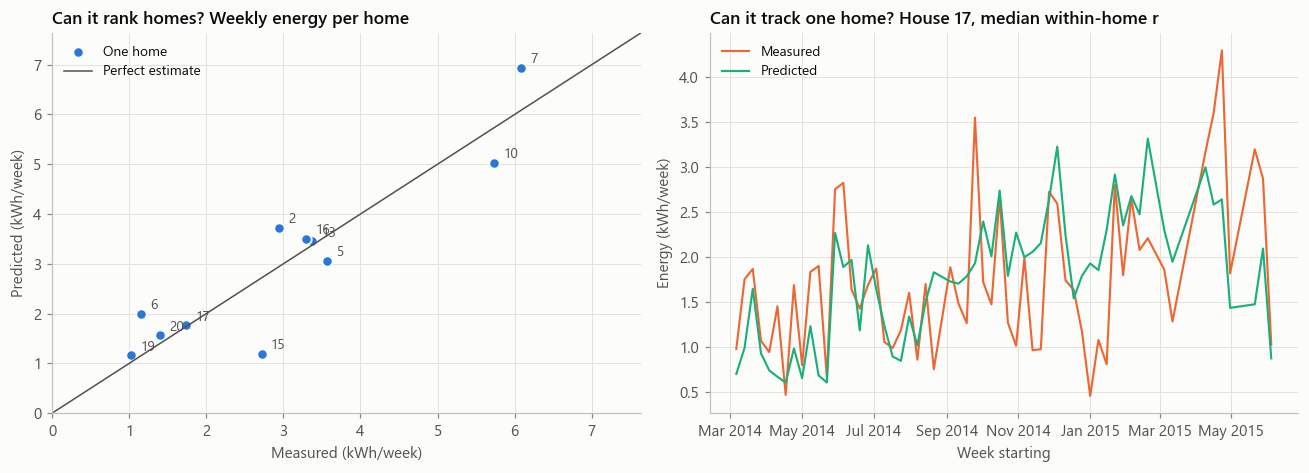

In [9]:
def weekly(table):
    rows_ok = table[table["eval_ok"]]
    grouped = rows_ok[["wm", "pred"]].resample("7D").sum() / 60_000
    count = rows_ok["wm"].resample("7D").count()
    return grouped[count >= 0.8 * 10080]

rows = []
for house in HOUSES:
    week = weekly(predictions["selected"][predictions["selected"]["house"] == house])
    wrong = (week["pred"] - week["wm"]).abs()
    rows.append({"House": house, "Weeks": len(week), "True kWh/week": week["wm"].mean(), "Predicted kWh/week": week["pred"].mean(),
                 "Weekly abs error %": 100 * wrong.mean() / week["wm"].mean(), "Average-home weekly abs error %": 100 * (week["wm"] - valid_means.drop(house).mean() * 10080 / 60_000 * 1).abs().mean() / week["wm"].mean(),
                 "Within-home weekly r": week["wm"].corr(week["pred"]), "Within-home weekly Spearman": week["wm"].corr(week["pred"], method="spearman")})
weekly_table = pd.DataFrame(rows).set_index("House")
weekly_table.round(3).to_csv(cfg.METRICS / "weekly_energy_accuracy.csv")
display(weekly_table.round(2))
print("Mean:", weekly_table.mean().round(2).to_dict())

true_rate, pred_rate = weekly_table["True kWh/week"], weekly_table["Predicted kWh/week"]
result = stats.spearmanr(true_rate, pred_rate)
print(f"Across homes, true vs predicted weekly energy: Spearman rho = {result.statistic:.2f}, p = {result.pvalue:.3f}; Pearson r = {true_rate.corr(pred_rate):.2f}")
threshold_week = pd.Series({h: weekly(predictions["threshold_rule"][predictions["threshold_rule"]["house"] == h])["pred"].mean() for h in HOUSES})
result_t = stats.spearmanr(true_rate, threshold_week)
print(f"Threshold rule, same comparison: Spearman rho = {result_t.statistic:.2f}, p = {result_t.pvalue:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
axes[0].scatter(true_rate, pred_rate, color=viz.BLUE, s=46, edgecolors=viz.SURFACE, linewidths=1.2, label="One home")
limit = max(true_rate.max(), pred_rate.max()) * 1.1
axes[0].plot([0, limit], [0, limit], color=viz.INK_2, linewidth=1, label="Perfect estimate")
for house in HOUSES:
    axes[0].annotate(str(house), (true_rate[house], pred_rate[house]), textcoords="offset points", xytext=(6, 3), fontsize=9, color=viz.INK_2)
axes[0].set_xlim(0, limit); axes[0].set_ylim(0, limit)
axes[0].set_title("Can it rank homes? Weekly energy per home")
axes[0].set_xlabel("Measured (kWh/week)"); axes[0].set_ylabel("Predicted (kWh/week)")
axes[0].legend(loc="upper left")
house_id = weekly_table["Within-home weekly r"].sort_values().index[len(HOUSES) // 2]
week = weekly(predictions["selected"][predictions["selected"]["house"] == house_id])
axes[1].plot(week.index, week["wm"], color=viz.ORANGE, label="Measured")
axes[1].plot(week.index, week["pred"], color=viz.AQUA, label="Predicted")
axes[1].set_title(f"Can it track one home? House {house_id}, median within-home r")
axes[1].set_xlabel("Week starting"); axes[1].set_ylabel("Energy (kWh/week)")
axes[1].xaxis.set_major_formatter(viz.mdates.DateFormatter("%b %Y"))
axes[1].legend(loc="upper left")
fig.tight_layout()
viz.save(fig, "03_weekly_energy")
plt.show()

### 5a. A stricter energy baseline: is the washing machine just a fixed share of the bill?

The weekly results above could come from the model recognising the machine, or simply from busier homes using more of everything. To separate these, the **fixed-share baseline** multiplies this home's weekly aggregate energy by the washing machine's average share in the other homes. It uses the aggregate and no appliance signature at all. If the model cannot beat this, its energy estimates add little.

In [10]:
evaluated_all = predictions["selected"][predictions["selected"]["eval_ok"]]
frames = {}
for house in HOUSES:
    group = evaluated_all[evaluated_all["house"] == house]
    aggregate = prepare_clean_house(house)["aggregate"].reindex(group.index)
    frames[house] = pd.DataFrame({"wm": group["wm"].astype(float), "pred": group["pred"].astype(float), "aggregate": aggregate.astype(float)}).dropna()
shares = pd.Series({house: frame["wm"].sum() / frame["aggregate"].sum() for house, frame in frames.items()})
print("Washing-machine share of household energy (%):", (100 * shares).round(2).to_dict())

rows = []
for house, frame in frames.items():
    week = frame.resample("7D").sum() / 60_000
    week = week[frame["wm"].resample("7D").count() >= 0.8 * 10080]
    baseline = week["aggregate"] * shares.drop(house).mean()
    rows.append({"House": house, "Weeks": len(week), "True kWh/week": week["wm"].mean(), "Model kWh/week": week["pred"].mean(), "Fixed-share kWh/week": baseline.mean(),
                 "Model weekly abs error %": 100 * (week["pred"] - week["wm"]).abs().mean() / week["wm"].mean(), "Fixed-share weekly abs error %": 100 * (baseline - week["wm"]).abs().mean() / week["wm"].mean(),
                 "Model within-home r": week["wm"].corr(week["pred"]), "Fixed-share within-home r": week["wm"].corr(baseline),
                 "Model total error %": 100 * (week["pred"].sum() - week["wm"].sum()) / week["wm"].sum(), "Fixed-share total error %": 100 * (baseline.sum() - week["wm"].sum()) / week["wm"].sum()})
share_table = pd.DataFrame(rows).set_index("House")
share_table.round(3).to_csv(cfg.METRICS / "model_vs_fixed_share_baseline.csv")
display(share_table.round(2))
print("Mean:", share_table.mean().round(2).to_dict())
print("Mean absolute total error %: model", round(share_table["Model total error %"].abs().mean(), 2), "fixed share", round(share_table["Fixed-share total error %"].abs().mean(), 2))
for name, a, b in (("Weekly abs error", "Model weekly abs error %", "Fixed-share weekly abs error %"), ("Within-home r", "Model within-home r", "Fixed-share within-home r")):
    difference = share_table[a] - share_table[b]
    print(f"{name}: model minus fixed share mean {difference.mean():.2f}; Wilcoxon p = {stats.wilcoxon(difference).pvalue:.4f}; model better in {(difference < 0).sum() if 'error' in name else (difference > 0).sum()} of {len(difference)} homes")
print("Across homes, rank correlation with true kWh/week: model", round(stats.spearmanr(share_table["True kWh/week"], share_table["Model kWh/week"]).statistic, 2), "fixed share", round(stats.spearmanr(share_table["True kWh/week"], share_table["Fixed-share kWh/week"]).statistic, 2))

Washing-machine share of household energy (%): {2: 3.96, 5: 3.06, 6: 1.48, 7: 6.69, 10: 5.26, 13: 4.12, 15: 6.78, 16: 3.54, 17: 2.79, 19: 2.18, 20: 2.23}


,Weeks,True kWh/week,Model kWh/week,Fixed-share kWh/week,Model weekly abs error %,Fixed-share weekly abs error %,Model within-home r,Fixed-share within-home r,Model total error %,Fixed-share total error %
House,,,,,,,,,,
2,61,2.95,3.73,2.85,35.79,30.14,0.54,0.26,26.46,-3.35
5,77,3.57,3.07,4.67,39.18,50.41,0.41,0.38,-14.15,30.75
6,65,1.16,2.00,3.17,77.71,177.95,0.46,0.30,72.56,173.58
7,69,6.08,6.94,3.33,21.18,46.28,0.76,0.59,14.05,-45.31
10,63,5.74,5.03,4.07,30.33,40.64,0.31,0.17,-12.25,-29.00
13,39,3.37,3.46,3.25,15.57,23.78,0.88,0.79,2.54,-3.43
15,61,2.72,1.20,1.48,56.85,54.72,0.93,0.38,-56.04,-45.74
16,55,3.29,3.50,3.59,22.62,23.77,0.77,0.74,6.35,8.85
17,59,1.74,1.77,2.41,32.04,49.41,0.57,0.40,1.43,38.39


Mean: {'Weeks': 60.45, 'True kWh/week': 3.0, 'Model kWh/week': 3.04, 'Fixed-share kWh/week': 3.02, 'Model weekly abs error %': 36.01, 'Fixed-share weekly abs error %': 60.4, 'Model within-home r': 0.61, 'Fixed-share within-home r': 0.42, 'Model total error %': 6.03, 'Fixed-share total error %': 26.27}
Mean absolute total error %: model 21.02 fixed share 49.33
Weekly abs error: model minus fixed share mean -24.39; Wilcoxon p = 0.0098; model better in 9 of 11 homes
Within-home r: model minus fixed share mean 0.19; Wilcoxon p = 0.0010; model better in 11 of 11 homes
Across homes, rank correlation with true kWh/week: model 0.83 fixed share 0.75


**The model beats this stricter baseline.** Weekly absolute error is 36.0% against 60.4% (better in 9 of 11 homes, p = 0.0098), and within-home tracking is r = 0.61 against 0.42 (better in all 11, p = 0.001). So the model has picked up signal specific to the machine, beyond how busy a home is.

**Where it does not win.**
- **Ranking homes:** rank correlation is 0.83 against 0.75. With 11 homes that gap is too small to count, and the earlier threshold rule reached 0.86.
- **Portfolio total:** the mean across homes is about right for both (true 3.00, model 3.04, fixed share 3.02 kWh/week). Knowing only the typical share gets the group total right, so no model is needed for that.

**This is the model's strongest result, but it is exploratory.** Weekly energy holds up better than minute-level power, because timing errors partly cancel out over a week.

- **Tracking change within a home is the strongest result:** mean r = 0.61, ranging from 0.31 (House 10) to 0.93 (House 15).
- **A single home's level is unreliable:** the mean weekly error is 36%, from 15.6% (House 13) to 77.7% (House 6).
- **House 15 shows these are separate abilities.** It has r = 0.93 but underestimates by 56%. So the model follows that home's changes well while getting the level wrong. A small per-home calibration might fix this, but that was not tested.

**Practical reading:** this does not support a message to one customer about their own change. Detecting a change in one home has not been validated.

### 5b. Against the threshold rule, and how much does the prediction move?

The slope is how far weekly predicted energy moves for each 1 kWh change in measured energy, fitted within one home.

In [11]:
rows = []
for house in HOUSES:
    week = weekly(predictions["selected"][predictions["selected"]["house"] == house])
    rule = weekly(predictions["threshold_rule"][predictions["threshold_rule"]["house"] == house])
    rows.append({"House": house, "Model within-home r": week["wm"].corr(week["pred"]), "Threshold rule within-home r": rule["wm"].corr(rule["pred"]), "Slope, predicted on measured": np.polyfit(week["wm"], week["pred"], 1)[0]})
tracking = pd.DataFrame(rows).set_index("House")
tracking.round(3).to_csv(cfg.METRICS / "weekly_tracking_vs_threshold_rule.csv")
display(tracking.round(2))
track_gap = tracking["Model within-home r"] - tracking["Threshold rule within-home r"]
print(f"Mean r: model {tracking['Model within-home r'].mean():.3f}, threshold rule {tracking['Threshold rule within-home r'].mean():.3f}; model better in {(track_gap > 0).sum()} of {len(track_gap)}; Wilcoxon p = {stats.wilcoxon(track_gap).pvalue:.4f}")
print(f"Model r range: {tracking['Model within-home r'].min():.2f} to {tracking['Model within-home r'].max():.2f}")
print(f"Slope: mean {tracking['Slope, predicted on measured'].mean():.2f}, range {tracking['Slope, predicted on measured'].min():.2f} to {tracking['Slope, predicted on measured'].max():.2f}")

,Model within-home r,Threshold rule within-home r,"Slope, predicted on measured"
House,,,
2,0.54,0.24,0.72
5,0.41,0.30,0.23
6,0.46,-0.01,0.42
7,0.76,0.63,0.89
10,0.31,0.05,0.17
13,0.88,0.81,0.65
15,0.93,0.70,0.40
16,0.77,0.72,0.79
17,0.57,0.47,0.48


Mean r: model 0.614, threshold rule 0.438; model better in 10 of 11; Wilcoxon p = 0.0020
Model r range: 0.31 to 0.93
Slope: mean 0.52, range 0.17 to 0.89


**The within-home signal is real, but muted.** The model beats the threshold rule too: mean r 0.61 against 0.44, better in 10 of 11 homes (p = 0.002), with House 19 the exception. But a 1 kWh change in measured weekly energy moves the prediction by only about 0.52 kWh on average, from 0.17 (House 10) and 0.23 (House 5) to 0.89 (House 7). So r alone overstates how well a change could be measured.

## 6. What does the model see? Accuracy by power level and by event

In [12]:
rows, event_tables = [], []
BANDS = [("1000+ W (heating)", 1000, np.inf), ("200-1000 W", 200, 1000), ("20-200 W (tumbling)", cfg.ACTIVE_W, 200)]
for house, group in predictions["selected"].groupby("house"):
    rows_ok = group[group["eval_ok"]]
    for name, low, high in BANDS:
        band = rows_ok[(rows_ok["wm"] > low) & (rows_ok["wm"] < high)] if low == cfg.ACTIVE_W else rows_ok[(rows_ok["wm"] >= low) & (rows_ok["wm"] < high)]
        rows.append({"house": house, "band": name, "minutes": len(band), "true_kwh": band["wm"].sum() / 60_000, "pred_kwh": band["pred"].sum() / 60_000,
                     "called_on_pct": 100 * (band["pred"] > thresholds["selected"][house]).mean() if len(band) else np.nan})
    off = rows_ok[rows_ok["wm"] <= cfg.ACTIVE_W]
    rows.append({"house": house, "band": "OFF (20 W or less)", "minutes": len(off), "true_kwh": off["wm"].sum() / 60_000, "pred_kwh": off["pred"].sum() / 60_000, "called_on_pct": 100 * (off["pred"] > thresholds["selected"][house]).mean()})
    table = event_energy_table(rows_ok["wm"], rows_ok["pred"], thresholds["selected"][house])
    event_tables.append(table.assign(house=house))
bands = pd.DataFrame(rows)
band_summary = bands.groupby("band").agg(minutes=("minutes", "sum"), true_kwh=("true_kwh", "sum"), pred_kwh=("pred_kwh", "sum"), called_on_pct=("called_on_pct", "mean"))
band_summary["true_energy_share_pct"] = 100 * band_summary["true_kwh"] / band_summary["true_kwh"].sum()
band_summary["pred_energy_share_pct"] = 100 * band_summary["pred_kwh"] / band_summary["pred_kwh"].sum()
band_summary.round(2).to_csv(cfg.METRICS / "accuracy_by_power_band.csv")
display(band_summary.round(2))

test_events = pd.concat(event_tables, ignore_index=True)
complete = test_events[~test_events["incomplete"]].copy()
complete["ape"] = 100 * (complete["pred_kwh"] - complete["energy_kwh"]).abs() / complete["energy_kwh"]
complete["found"] = complete["on_share"] >= 0.25
per_house = complete.groupby("house").agg(events=("found", "size"), found_pct=("found", lambda s: 100 * s.mean()), median_true_kwh=("energy_kwh", "median"), median_pred_kwh=("pred_kwh", "median"), median_abs_pct_err=("ape", "median"), median_heater_min=("heater_min", "median"))
per_house.round(2).to_csv(cfg.METRICS / "event_energy_accuracy.csv")
display(per_house.round(2))
print(f"Complete true events: {len(complete):,}. Median absolute error in energy per event: {complete['ape'].median():.1f}%")
print("Overall correlation, per-event true vs predicted kWh:", round(complete["energy_kwh"].corr(complete["pred_kwh"]), 3))
complete["heater_band"] = pd.cut(complete["heater_min"], [-1, 0, 5, 15, 30, 1e6], labels=["none", "1-5", "6-15", "16-30", "over 30"])
by_heater = complete.groupby("heater_band", observed=True).agg(events=("found", "size"), found_pct=("found", lambda s: 100 * s.mean()), true_kwh=("energy_kwh", "median"), pred_kwh=("pred_kwh", "median"), median_abs_pct_err=("ape", "median"))
by_heater.round(2).to_csv(cfg.METRICS / "event_recall_by_heater_minutes.csv")
print("By minutes at 1000+ W in the event:")
display(by_heater.round(2))

,minutes,true_kwh,pred_kwh,called_on_pct,true_energy_share_pct,pred_energy_share_pct
band,,,,,,
1000+ W (heating),51093,1688.560059,544.789978,96.33,73.129997,23.719999
20-200 W (tumbling),249462,370.850006,276.519989,58.04,16.059999,12.040000
200-1000 W,37755,224.339996,46.349998,71.42,9.720000,2.020000
OFF (20 W or less),6887993,25.129999,1428.900024,8.04,1.090000,62.220001


,events,found_pct,median_true_kwh,median_pred_kwh,median_abs_pct_err,median_heater_min
house,,,,,,
2,281,57.65,0.64,0.22,65.54,15.0
5,601,88.85,0.28,0.06,78.34,6.0
6,110,99.09,0.68,0.34,48.86,15.0
7,777,99.87,0.55,0.29,45.60,13.0
10,545,99.27,0.72,0.25,64.31,15.0
13,270,100.00,0.46,0.17,65.17,11.0
15,239,90.79,0.71,0.27,66.36,16.0
16,288,99.31,0.64,0.18,72.03,16.0
17,271,94.83,0.38,0.11,70.91,10.0


Complete true events: 3,809. Median absolute error in energy per event: 66.3%
Overall correlation, per-event true vs predicted kWh: 0.704
By minutes at 1000+ W in the event:


,events,found_pct,true_kwh,pred_kwh,median_abs_pct_err
heater_band,,,,,
none,197,63.96,0.06,0.01,82.04
1-5,503,62.03,0.22,0.04,82.75
6-15,2027,93.88,0.48,0.18,64.72
16-30,962,95.43,0.75,0.30,61.78
over 30,120,95.83,1.42,0.54,64.43


**The most important finding in this notebook: total energy is right partly for the wrong reasons.**

| Machine state | Measured kWh | Predicted kWh |
|---|---|---|
| Heating, 1000+ W | 1,689 | 545 |
| 200-1000 W | 224 | 46 |
| Tumbling, 20-200 W | 371 | 277 |
| OFF, 20 W or less | 25 | **1,429** |
| **Total** | **2,309** | **2,297** |

The totals agree to within 1%, but **62% of predicted energy falls in minutes when the machine is off**, and heating energy is underestimated by two-thirds. These errors cancel. Training on squared error tends to produce this: when unsure, the model predicts a low average value over many minutes, so the total stays about right even when the timing is wrong.

So a small total-energy error **is not evidence that the model finds washing cycles**. Any report quoting only that number would mislead.

**Per event, the picture is honest and weak.** The median absolute error in a complete event's energy is 66.3%, and predicted energy is about a third of measured. An event's predicted and measured energy do correlate (r = 0.70), so bigger cycles do look bigger.

**More heating makes a cycle easier to find.** Events with 6+ minutes of heating are found 94-96% of the time, against 62-64% with 5 minutes or fewer. Here "found" means at least 25% of an event's minutes are called ON.

### 6a. Detection by machine state, under two definitions

**Machine is on** asks whether the model called the machine ON during this state. Recall is the share of this state's minutes called ON. Precision compares this state with OFF minutes only, because calling ON during a different active state is not a false alarm, so these precisions do not add up to the overall one. **Correct power band** is stricter: the predicted watts must fall in the same band as the measured watts. Bands are 20-200 W (above 20, below 200), 200-1000 W (from 200, below 1000) and 1000+ W. Values are the mean of 11 homes.

In [13]:
STATES = [("Heating, 1000+ W", lambda s: s >= 1000), ("Medium, 200-1000 W", lambda s: (s >= 200) & (s < 1000)), ("Tumbling, 20-200 W", lambda s: (s > cfg.ACTIVE_W) & (s < 200))]
def state_scores_for(actual, called, wrong):
    """``wrong`` marks the minutes that count as a false alarm when they are called."""
    hits = int((actual & called).sum())
    alarms = int((wrong & called).sum())
    precision = hits / (hits + alarms) if hits + alarms else 0.0
    recall = hits / actual.sum() if actual.sum() else 0.0
    return precision, recall, (2 * precision * recall / (precision + recall) if precision + recall else 0.0)
rows = []
for house, group in predictions["selected"].groupby("house"):
    rows_ok = group[group["eval_ok"]]
    y, pred = rows_ok["wm"].to_numpy(float), rows_ok["pred"].to_numpy(float)
    called_on = pred > thresholds["selected"][house]
    for name, in_state in STATES:
        rows.append({"House": house, "State": name, "Definition": "Machine is on", **dict(zip(("Precision", "Recall", "F1"), state_scores_for(in_state(y), called_on, y <= cfg.ACTIVE_W)))})
        rows.append({"House": house, "State": name, "Definition": "Correct power band", **dict(zip(("Precision", "Recall", "F1"), state_scores_for(in_state(y), in_state(pred), ~in_state(y))))})
state_table = pd.DataFrame(rows).groupby(["State", "Definition"], sort=False)[["Precision", "Recall", "F1"]].mean()
state_table.round(3).to_csv(cfg.METRICS / "per_state_detection.csv")
display(state_table.round(2))

Precision  Recall    F1
State              Definition                                 
Heating, 1000+ W   Machine is on            0.11    0.96  0.18
                   Correct power band       0.55    0.19  0.28
Medium, 200-1000 W Machine is on            0.07    0.71  0.11
                   Correct power band       0.01    0.05  0.02
Tumbling, 20-200 W Machine is on            0.22    0.58  0.30
                   Correct power band       0.22    0.63  0.31

**The model notices heating, but rarely gets its size right.** Heating minutes are called ON 96% of the time, yet the predicted watts land in the heating band only 20% of the time. The medium band is almost never identified (F1 0.02). This fits the energy table above: heating is under-predicted, and low predictions spread across many minutes.

## 7. Unseen homes versus future of known homes

For a fair comparison, both results below use the same test minutes: the last 30% of each home. The only difference is whether the model has seen that home. The table shows the model most often selected on validation houses, and the other model's means are printed below it.

In [14]:
FINAL = saved["method"]
print("Model most often selected on validation houses:", FINAL)
def compare_known_unseen(method):
    later_all, later_limits = load_predictions("temporal", method)
    unseen_all, unseen_limits = predictions[method], thresholds[method]
    rows = []
    for house in HOUSES:
        later = later_all[later_all["house"] == house]
        unseen = unseen_all[unseen_all["house"] == house].reindex(later.index)
        unseen = unseen[unseen["pred"].notna()]
        unseen = unseen.assign(eval_ok=unseen["eval_ok"].astype(bool))
        known_result = evaluate(later, later_limits[house], with_events=False)
        unseen_result = evaluate(unseen, unseen_limits[house], with_events=False)
        rows.append({"House": house, "F1 unseen": unseen_result["F1"], "F1 known": known_result["F1"], "R2 unseen": unseen_result["R2"], "R2 known": known_result["R2"],
                     "MAE ON unseen": unseen_result["MAE_ON"], "MAE ON known": known_result["MAE_ON"],
                     "Energy err % unseen": unseen_result["Energy_error_pct"], "Energy err % known": known_result["Energy_error_pct"]})
    table = pd.DataFrame(rows).set_index("House")
    table["Abs energy err % unseen"] = table["Energy err % unseen"].abs()
    table["Abs energy err % known"] = table["Energy err % known"].abs()
    return table

temporal = compare_known_unseen(FINAL)
temporal.round(3).to_csv(cfg.METRICS / "temporal_vs_unseen_homes.csv")
display(temporal.round(2))
print("Mean:", temporal.mean().round(3).to_dict())
print(f"Homes with higher F1 when seen before: {(temporal['F1 known'] > temporal['F1 unseen']).sum()} of {len(temporal)}; Wilcoxon p = {stats.wilcoxon(temporal['F1 known'] - temporal['F1 unseen']).pvalue:.4f}")
other = "random_forest" if FINAL != "random_forest" else "hist_gradient_boosting"
temporal_other = compare_known_unseen(other)
temporal_other.round(3).to_csv(cfg.METRICS / f"temporal_vs_unseen_homes_{other}.csv")
print(f"The other model ({other}), mean:", temporal_other.mean().round(3).to_dict())

Model most often selected on validation houses: hist_gradient_boosting


,F1 unseen,F1 known,R2 unseen,R2 known,MAE ON unseen,MAE ON known,Energy err % unseen,Energy err % known,Abs energy err % unseen,Abs energy err % known
House,,,,,,,,,,
2,0.28,0.30,0.14,0.22,306.60,293.78,45.31,36.04,45.31,36.04
5,0.35,0.34,0.14,0.14,344.53,344.06,-37.31,-39.36,37.31,39.36
6,0.19,0.27,0.56,0.60,210.76,200.69,90.07,74.97,90.07,74.97
7,0.60,0.61,0.50,0.57,279.98,256.83,6.71,3.22,6.71,3.22
10,0.37,0.43,0.29,0.39,279.18,244.17,15.42,24.61,15.42,24.61
13,0.49,0.57,0.30,0.39,348.64,327.16,-18.57,-17.05,18.57,17.05
15,0.74,0.71,0.61,0.75,379.57,286.28,-56.62,-39.15,56.62,39.15
16,0.35,0.35,0.28,0.33,406.25,387.03,8.21,9.65,8.21,9.65
17,0.40,0.41,0.36,0.41,301.15,287.83,0.04,3.24,0.04,3.24


Mean: {'F1 unseen': 0.382, 'F1 known': 0.412, 'R2 unseen': 0.271, 'R2 known': 0.356, 'MAE ON unseen': 297.763, 'MAE ON known': 275.271, 'Energy err % unseen': 6.36, 'Energy err % known': 6.761, 'Abs energy err % unseen': 26.813, 'Abs energy err % known': 24.135}
Homes with higher F1 when seen before: 7 of 11; Wilcoxon p = 0.0830


The other model (random_forest), mean: {'F1 unseen': 0.388, 'F1 known': 0.46, 'R2 unseen': 0.269, 'R2 known': 0.348, 'MAE ON unseen': 299.291, 'MAE ON known': 275.886, 'Energy err % unseen': 8.876, 'Energy err % known': 8.575, 'Abs energy err % unseen': 28.131, 'Abs energy err % known': 24.809}


**Having seen a home helps, but only a little.** On identical minutes, F1 rises from 0.38 to 0.41 and R² from 0.27 to 0.36, with 7 of 11 homes improving (p = 0.083). Absolute energy error moves from 26.8% to 24.1%. The Random Forest shows a similar pattern, with F1 rising from 0.39 to 0.46.

**What this suggests.** Unfamiliarity with a home is not the main limit. Even with a home's own history available, the signal stays ambiguous, because other loads look like the machine in the aggregate.

**Limit:** the "known home" model is still one shared model trained on all homes. A model fitted to each home alone could do better, and that was not tested. These results also must not be presented as performance on new homes. That is what leave one house out measures.

## 8. What if the meter reads only every 15 or 30 minutes?

Aggregate and washing-machine power are averaged to the coarser interval, then both models are retrained and tested on unseen homes. **ON has a different meaning at each resolution**, because a 30-minute average above 20 W can come from a short burst. So compare energy error and R² across resolutions with more confidence than F1. All three are on their own period and row set.

In [15]:
rows = []
for method in (FINAL, other):
    for label, experiment, step in (("1 minute", "loho", 1), ("15 minutes", "loho_15min", 15), ("30 minutes", "loho_30min", 30)):
        table, limits = load_predictions(experiment, method)
        result = evaluate_by_house(table, limits, step_min=step, with_events=False)
        result["Abs_energy_error_pct"] = result["Energy_error_pct"].abs()
        rows.append({"Model": method, "Resolution": label, "Rows evaluated": int(result["Minutes"].sum()), "ON %": result["ON_pct"].mean(), "MAE (W)": result["MAE"].mean(), "RMSE (W)": result["RMSE"].mean(), "R2": result["R2"].mean(), "MAE ON (W)": result["MAE_ON"].mean(), "F1": result["F1"].mean(),
                     "Mean abs energy error %": result["Abs_energy_error_pct"].mean(), "Median abs energy error %": result["Abs_energy_error_pct"].median()})
        del table
resolution = pd.DataFrame(rows).set_index(["Model", "Resolution"])
resolution.round(3).to_csv(cfg.METRICS / "resolution_comparison.csv")
display(resolution.round(2))
gc.collect()

Rows evaluated  ON %  MAE (W)  RMSE (W)    R2  MAE ON (W)    F1  Mean abs energy error %  Median abs energy error %
Model                  Resolution                                                                                                                     
hist_gradient_boosting 1 minute           7226303  4.60    25.08    133.41  0.26      290.73  0.38                    22.18                      12.48
                       15 minutes          477266  5.40    28.05    119.08  0.03      267.13  0.34                    27.58                      26.89
                       30 minutes          234758  6.11    28.47    102.24 -0.07      236.44  0.35                    34.86                      27.27
random_forest          1 minute           7226303  4.60    25.48    134.43  0.25      292.23  0.39                    21.99                       9.86
                       15 minutes          477266  5.40    28.15    117.82  0.06      261.89  0.36                    28.64                      27.25
                       30 minutes          234758  6.11    28.60    100.81 -0.02      232.02  0.36                    36.10                      28.13

25

In [16]:
# Weekly results at each meter rate. Energy = sum(W) x interval minutes / 60,000.
def weekly_at(table, step):
    rows_ok = table[table["eval_ok"]]
    week = rows_ok[["wm", "pred", "aggregate"]].astype(float).resample("7D").sum() * step / 60_000
    return week[rows_ok["wm"].resample("7D").count() >= 0.8 * 10080 / step]

rows = []
for method in ("hist_gradient_boosting", "random_forest"):
    for label, experiment, step in (("1 minute", "loho", 1), ("15 minutes", "loho_15min", 15), ("30 minutes", "loho_30min", 30)):
        table, _ = load_predictions(experiment, method)
        with_aggregate = {}
        for house in HOUSES:
            group = table[table["house"] == house]
            aggregate = to_resolution(prepare_clean_house(house), step)["aggregate"].reindex(group.index)
            with_aggregate[house] = group.assign(aggregate=aggregate).dropna(subset=["aggregate"])
        rate_shares = pd.Series({house: frame.loc[frame["eval_ok"], "wm"].sum() / frame.loc[frame["eval_ok"], "aggregate"].sum() for house, frame in with_aggregate.items()})
        for house, frame in with_aggregate.items():
            week = weekly_at(frame, step)
            baseline = week["aggregate"] * rate_shares.drop(house).mean()
            rows.append({"Model": method, "Resolution": label, "House": house, "Weeks": len(week), "Model r": week["wm"].corr(week["pred"]), "Fixed-share r": week["wm"].corr(baseline),
                         "Model weekly abs error %": 100 * (week["pred"] - week["wm"]).abs().mean() / week["wm"].mean(), "Fixed-share weekly abs error %": 100 * (baseline - week["wm"]).abs().mean() / week["wm"].mean()})
        del table, with_aggregate
        gc.collect()
weekly_resolution_homes = pd.DataFrame(rows)
weekly_resolution_homes.round(3).to_csv(cfg.METRICS / "weekly_by_resolution_by_house.csv", index=False)
grouped = weekly_resolution_homes.assign(Beats=lambda d: d["Model r"] > d["Fixed-share r"]).groupby(["Model", "Resolution"], sort=False)
weekly_resolution = grouped.agg(Homes=("House", "size"), Weeks=("Weeks", "sum"), Mean_r=("Model r", "mean"), Min_r=("Model r", "min"), Max_r=("Model r", "max"), Fixed_share_r=("Fixed-share r", "mean"), Weekly_abs_error=("Model weekly abs error %", "mean"), Fixed_share_abs_error=("Fixed-share weekly abs error %", "mean"), Homes_beating_fixed_share=("Beats", "sum"))
weekly_resolution.round(3).to_csv(cfg.METRICS / "weekly_by_resolution.csv")
display(weekly_resolution.round(3))

Homes  Weeks  Mean_r  Min_r  Max_r  Fixed_share_r  Weekly_abs_error  Fixed_share_abs_error  Homes_beating_fixed_share
Model                  Resolution                                                                                                                       
hist_gradient_boosting 1 minute       11    665   0.635  0.306  0.925          0.423            36.455                 60.402                         11
                       15 minutes     11    655   0.564  0.241  0.897          0.439            42.211                 59.945                         10
                       30 minutes     11    632   0.541  0.195  0.858          0.453            47.838                 60.128                          9
random_forest          1 minute       11    665   0.607  0.287  0.929          0.423            36.519                 60.402                         11
                       15 minutes     11    655   0.585  0.275  0.895          0.439            43.108                 59.945                         10
                       30 minutes     11    632   0.545  0.196  0.870          0.453            49.639                 60.128                          9

**Coarser meters lose minute-level detail, but weekly tracking degrades rather than disappears.** For the selected model type:

| Resolution | R² | Mean abs energy error | Median abs energy error | Weekly r (range) | Weekly abs error | Homes beating fixed-share r |
|---|---|---|---|---|---|---|
| 1 minute | 0.26 | 22.2% | 12.5% | 0.635 (0.31-0.93) | 36.5% | 11 of 11 |
| 15 minutes | 0.03 | 27.6% | 26.9% | 0.564 (0.24-0.90) | 42.2% | 10 of 11 |
| 30 minutes | -0.07 | 34.9% | 27.3% | 0.541 (0.20-0.86) | 47.8% | 9 of 11 |

At 15 and 30 minutes R² is about zero, so the model is **not usable for power or cycle-level detail**. Lower RMSE at coarse resolution should not be mistaken for improvement, because averaging shrinks the peaks themselves. F1 is similar across resolutions, but ON means something different at each one, so it is not comparable. Events were not scored at these rates.

**Weekly tracking.** The Random Forest shows the same pattern (r 0.607, 0.585, 0.545; error 36.5%, 43.1%, 49.6%). Fixed share is computed on matching rows at each rate (r 0.42, 0.44, 0.45; error 60.4%, 59.9%, 60.1%). This is exploratory, and it remains unvalidated. The meter rate actually available is an open question, and it decides how much this matters.

## 9. Required plots

All use test predictions from the home the model never saw. The example home is the one with the median F1.

Example home: 16 (F1 0.34)


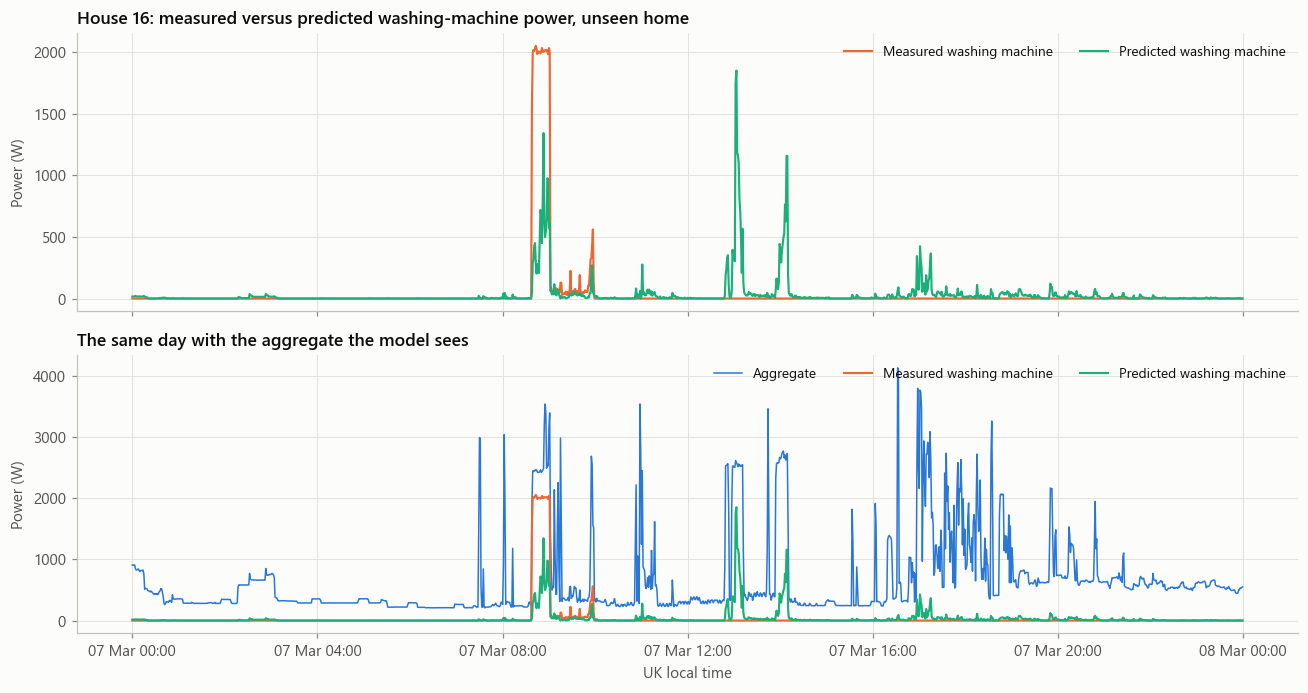

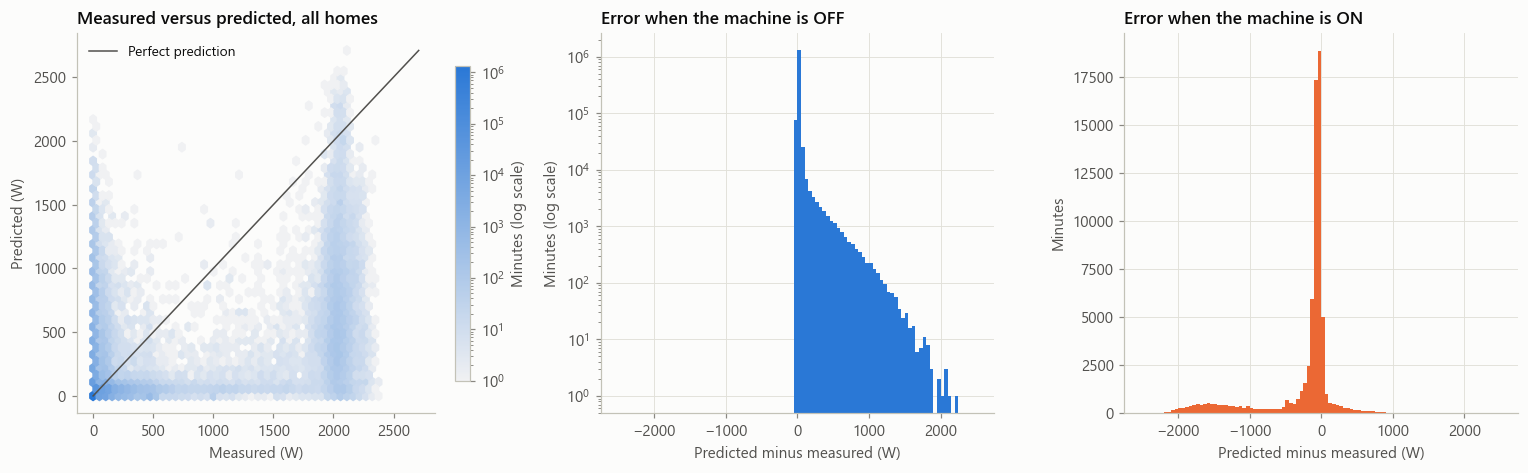

When ON: mean error -252 W, median -65 W. When OFF: mean 12.2 W, median 0.1 W; share within 20 W 90.4%


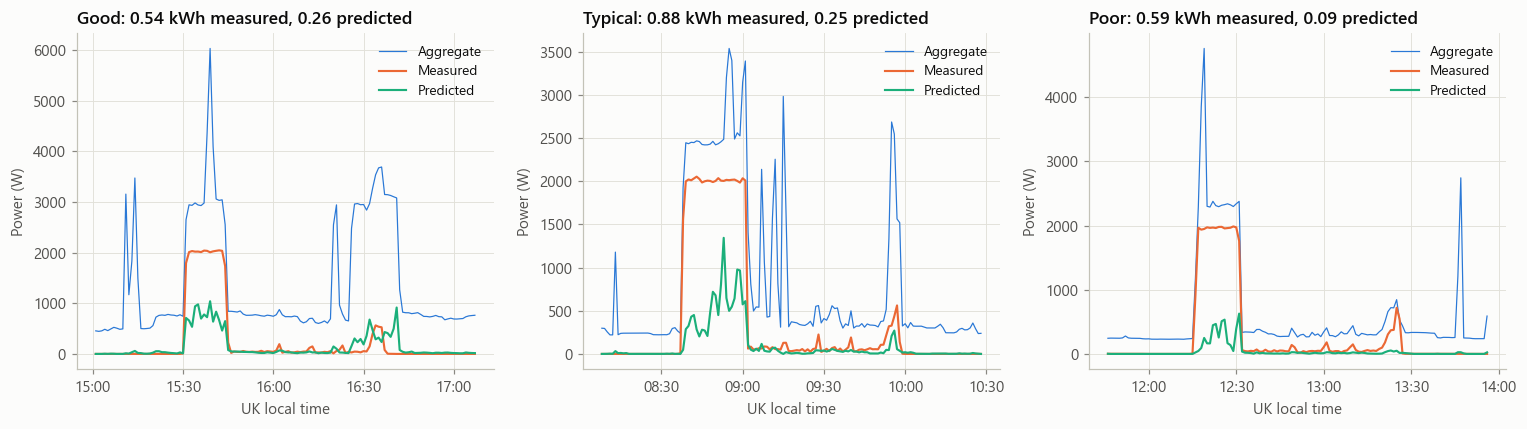

In [17]:
rank = selected["F1"].sort_values()
EXAMPLE = rank.index[len(rank) // 2]
print(f"Example home: {EXAMPLE} (F1 {rank[EXAMPLE]:.2f})")
minute = prepare_clean_house(EXAMPLE)
example = predictions["selected"][predictions["selected"]["house"] == EXAMPLE].copy()
example["aggregate"] = minute["aggregate"].reindex(example.index)
example["local_time"] = minute["local_time"].reindex(example.index)
example_events = test_events[(test_events["house"] == EXAMPLE) & ~test_events["incomplete"]].copy()
example_events["error"] = (example_events["pred_kwh"] - example_events["energy_kwh"]).abs() / example_events["energy_kwh"]
middle = example_events.iloc[(example_events["error"] - example_events["error"].median()).abs().argsort().iloc[0]]

# Required plots 1 and 2.
day_start = middle["start"].floor("D") + pd.Timedelta(hours=0)
day = example[(example.index >= day_start) & (example.index < day_start + pd.Timedelta(days=1))]
fig, axes = plt.subplots(2, 1, figsize=(12, 6.4), sharex=True)
axes[0].plot(day["local_time"], day["wm"], color=viz.ORANGE, label="Measured washing machine")
axes[0].plot(day["local_time"], day["pred"], color=viz.AQUA, label="Predicted washing machine")
axes[0].set_title(f"House {EXAMPLE}: measured versus predicted washing-machine power, unseen home")
axes[0].set_ylabel("Power (W)")
axes[0].legend(loc="upper right", ncols=2)
axes[1].plot(day["local_time"], day["aggregate"], color=viz.BLUE, linewidth=1, label="Aggregate")
axes[1].plot(day["local_time"], day["wm"], color=viz.ORANGE, label="Measured washing machine")
axes[1].plot(day["local_time"], day["pred"], color=viz.AQUA, label="Predicted washing machine")
axes[1].set_title("The same day with the aggregate the model sees")
axes[1].set_ylabel("Power (W)"); axes[1].set_xlabel("UK local time")
axes[1].legend(loc="upper right", ncols=3)
viz.format_time_axis(axes[1], "%d %b %H:%M")
fig.tight_layout()
viz.save(fig, "03_A_actual_vs_predicted_timeseries")
plt.show()

# Required plots 3 and 4.
pool = predictions["selected"][predictions["selected"]["eval_ok"]]
sample = pool.sample(min(1_500_000, len(pool)), random_state=cfg.RANDOM_SEED)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
image = axes[0].hexbin(sample["wm"], sample["pred"], gridsize=45, bins="log", cmap=sns.light_palette(viz.BLUE, as_cmap=True), mincnt=1)
limit = max(sample["wm"].max(), sample["pred"].max())
axes[0].plot([0, limit], [0, limit], color=viz.INK_2, linewidth=1, label="Perfect prediction")
axes[0].set_title("Measured versus predicted, all homes")
axes[0].set_xlabel("Measured (W)"); axes[0].set_ylabel("Predicted (W)")
axes[0].legend(loc="upper left"); axes[0].grid(False)
fig.colorbar(image, ax=axes[0], label="Minutes (log scale)", fraction=0.04)
error = sample["pred"] - sample["wm"]
on = sample["wm"] > cfg.ACTIVE_W
bins = np.arange(-2500, 2501, 50)
axes[1].hist(error[~on], bins=bins, color=viz.BLUE)
axes[1].set_yscale("log")
axes[1].set_title("Error when the machine is OFF")
axes[1].set_xlabel("Predicted minus measured (W)"); axes[1].set_ylabel("Minutes (log scale)")
axes[2].hist(error[on], bins=bins, color=viz.ORANGE)
axes[2].set_title("Error when the machine is ON")
axes[2].set_xlabel("Predicted minus measured (W)"); axes[2].set_ylabel("Minutes")
fig.tight_layout()
viz.save(fig, "03_B_scatter_and_error_distribution")
plt.show()
print(f"When ON: mean error {error[on].mean():.0f} W, median {error[on].median():.0f} W. When OFF: mean {error[~on].mean():.1f} W, median {error[~on].median():.1f} W; share within 20 W {100 * (error[~on].abs() <= 20).mean():.1f}%")

# Required plot 5: good, typical and poor events from the example home.
ranked = example_events.sort_values("error")
picks = [(ranked.iloc[len(ranked) // 10], "Good"), (middle, "Typical"), (ranked.iloc[int(len(ranked) * 0.9)], "Poor")]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (event, tag) in zip(axes, picks):
    window = example[(example.index >= event["start"] - pd.Timedelta(minutes=30)) & (example.index <= event["end"] + pd.Timedelta(minutes=30))]
    ax.plot(window["local_time"], window["aggregate"], color=viz.BLUE, linewidth=0.8, label="Aggregate")
    ax.plot(window["local_time"], window["wm"], color=viz.ORANGE, label="Measured")
    ax.plot(window["local_time"], window["pred"], color=viz.AQUA, label="Predicted")
    ax.set_title(f"{tag}: {event['energy_kwh']:.2f} kWh measured, {event['pred_kwh']:.2f} predicted")
    ax.set_xlabel("UK local time"); ax.set_ylabel("Power (W)")
    viz.format_time_axis(ax, "%H:%M")
    ax.legend(loc="upper right")
fig.tight_layout()
viz.save(fig, "03_C_event_comparison")
plt.show()

sample_rows = day[["wm", "pred", "aggregate", "local_time"]].rename(columns={"wm": "measured_w", "pred": "predicted_w", "aggregate": "aggregate_w"})
sample_path = cfg.PREDICTIONS / f"sample_predictions_house{EXAMPLE}.csv"
if not sample_path.exists():  # saved predictions are never overwritten
    sample_rows.to_csv(sample_path)

**What these show.**

**Time series.** House 16 is the median home. At about 08:45 the model detects the real wash, but reaches only 500-1,300 W of the true 2,000 W. At about 13:00-14:00 it raises a false alarm on 2.5 kW blocks that look just like the heater. The model sees only the past, so it cannot tell how long a block will last.

**Scatter.** Two features stand out. A column at about 2,000 W measured spreads over the full range of predictions, so heating is often badly underestimated. A row along zero predicted shows many active minutes are missed entirely. A perfect model would follow the diagonal.

**Errors.** When OFF, most errors are tiny: the median is 0.1 W and 90.4% are within 20 W, but a long tail reaches about 2,000 W. When ON, the mean is -252 W and the median -65 W, with a second hump near -1,500 W, heating that the model nearly missed.

**Event comparison.** Events are picked by rank of energy error in House 16. Even the "good" event's predicted energy (0.26 kWh) is about half of measured (0.54 kWh). The shape of the event is found much more reliably than its size.

**By home.** F1 ranges from 0.23 to 0.72. The threshold rule beats the model only in House 19. Energy errors go both ways, which is why they cancel in the average.

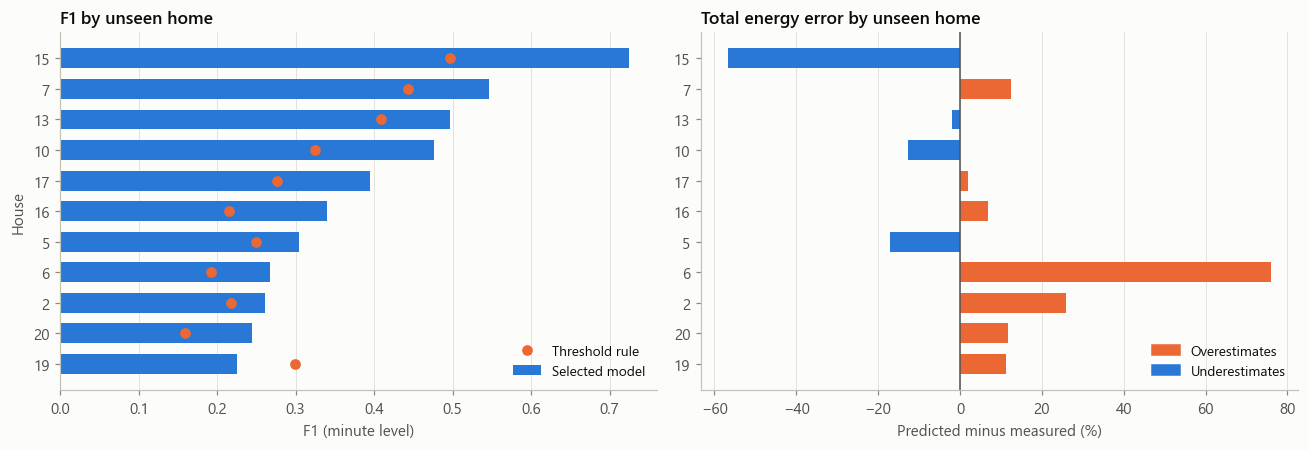

In [18]:
order = selected["F1"].sort_values().index.astype(str)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].barh(order, selected["F1"].sort_values(), color=viz.BLUE, height=0.65, label="Selected model")
axes[0].plot(by_house["threshold_rule"].loc[selected["F1"].sort_values().index, "F1"], order, "o", color=viz.ORANGE, label="Threshold rule")
axes[0].set_title("F1 by unseen home"); axes[0].set_xlabel("F1 (minute level)"); axes[0].set_ylabel("House")
axes[0].legend(loc="lower right"); axes[0].grid(axis="y", visible=False)
ordered = selected.loc[selected["F1"].sort_values().index, "Energy_error_pct"]
axes[1].barh(order, ordered, color=[viz.ORANGE if v > 0 else viz.BLUE for v in ordered], height=0.65)
axes[1].axvline(0, color=viz.INK_2, linewidth=1)
axes[1].set_title("Total energy error by unseen home"); axes[1].set_xlabel("Predicted minus measured (%)")
axes[1].grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=viz.ORANGE), plt.Rectangle((0, 0), 1, 1, color=viz.BLUE)]
axes[1].legend(handles, ["Overestimates", "Underestimates"], loc="lower right")
fig.tight_layout()
viz.save(fig, "03_D_results_by_home")
plt.show()

## 10. Failure analysis

### Case 1: why does the model raise so many false alarms?

The other sub-meters show what was actually running during false alarms. These channels are never model inputs; they are used here only to explain errors after the fact.

In [19]:
def attribute_false_alarms(house, active_w=100):
    """Which monitored appliance was running while the model wrongly said the machine was on?"""
    names = parse_readme()[house]
    raw = read_clean_csv(house, ["Unix", *cfg.APPLIANCES])
    raw["utc"] = clean_file_true_utc(raw["Unix"])
    raw = raw.dropna(subset=["utc"]).set_index("utc").drop(columns="Unix").astype("float32")
    channels = raw[cfg.APPLIANCES].clip(upper=cfg.APPLIANCE_MAX_W).resample("1min").mean()
    del raw
    group = predictions["selected"][predictions["selected"]["house"] == house]
    group = group[group["eval_ok"]]
    channels = channels.reindex(group.index)
    false_alarm = (group["wm"] <= cfg.ACTIVE_W) & (group["pred"] > thresholds["selected"][house])
    weight = group.loc[false_alarm, "pred"]
    rows = []
    any_running = pd.Series(False, index=weight.index)
    washer = f"Appliance{wm_channel(house)}"
    for channel in cfg.APPLIANCES:
        if channel == washer:
            continue
        running = channels[channel] > active_w
        any_running |= running.reindex(weight.index).fillna(False).astype(bool)
        rows.append({"House": house, "Appliance": names[int(channel[-1])].split(",")[0], "Running in false alarms (share of predicted energy, %)": 100 * weight[running.reindex(weight.index).fillna(False).astype(bool)].sum() / weight.sum(),
                     "Running in all OFF minutes (%)": 100 * running[group["wm"] <= cfg.ACTIVE_W].mean()})
    table = pd.DataFrame(rows)
    table["Lift"] = table.iloc[:, 2] / table.iloc[:, 3].clip(lower=0.01)
    print(f"House {house}: false-alarm minutes {int(false_alarm.sum()):,}; predicted energy in false alarms {weight.sum() / 60_000:.0f} kWh; measured washing-machine energy {group['wm'].sum() / 60_000:.0f} kWh")
    print(f"  Share of false-alarm energy with no monitored appliance above {active_w} W: {100 * weight[~any_running].sum() / weight.sum():.1f}%")
    return table.sort_values(table.columns[2], ascending=False)

CASES = [int(selected["Event_precision_original"].idxmin()), int(selected["F1"].sort_values().index[1])]
attribution = []
for house in dict.fromkeys(CASES):
    result = attribute_false_alarms(house)
    display(result.round(2))
    attribution.append(result)
    gc.collect()
pd.concat(attribution).round(2).to_csv(cfg.METRICS / "false_alarm_attribution.csv", index=False)

House 6: false-alarm minutes 62,239; predicted energy in false alarms 80 kWh; measured washing-machine energy 81 kWh
  Share of false-alarm energy with no monitored appliance above 100 W: 14.0%


,House,Appliance,"Running in false alarms (share of predicted energy, %)",Running in all OFF minutes (%),Lift
2,6,MJY Computer,62.139999,32.91,1.89
3,6,TV/Satellite,34.330002,21.57,1.59
1,6,Dishwasher,23.530001,0.47,49.83
5,6,Kettle,13.210000,1.39,9.51
4,6,Microwave,9.150000,0.93,9.83
6,6,Toaster,1.850000,0.38,4.87
7,6,PGM Computer,1.130000,0.48,2.34
0,6,Freezer,0.440000,0.43,1.03


House 20: false-alarm minutes 38,170; predicted energy in false alarms 57 kWh; measured washing-machine energy 83 kWh
  Share of false-alarm energy with no monitored appliance above 100 W: 20.2%


,House,Appliance,"Running in false alarms (share of predicted energy, %)",Running in all OFF minutes (%),Lift
1,20,Freezer,53.549999,43.93,1.22
3,20,Dishwasher,22.250000,0.53,42.01
2,20,Tumble Dryer,13.910000,1.49,9.36
7,20,Kettle,8.050000,0.78,10.35
6,20,Microwave,6.940000,0.55,12.53
4,20,Computer Site,6.800000,3.22,2.11
0,20,Fridge,0.600000,0.35,1.69
5,20,Television Site,0.430000,0.20,2.16


**Dishwashers are the strongest confusion found.** In House 6 a dishwasher runs during 23.5% of false-alarm energy, although it is on in only 0.47% of OFF minutes, about 50 times more than chance. House 20 shows the same pattern (22.3% against 0.53%, about 42 times). A dishwasher also heats water in blocks of about 2 kW and then runs a pump, so at 1 minute it can look much like a washing machine.

Other heating appliances are also overrepresented, at about 10 times chance: kettles (House 6: 9.5; House 20: 10.4), microwaves (9.8 and 12.5), and the tumble dryer in House 20 (9.4). Computers appear often, but they are on much of the time anyway, so their lift is under 2.5.

**Scale of the problem.** In House 6, predicted energy in false alarms (80 kWh) is about equal to the machine's whole measured energy (81 kWh).

**Limits.** This is the strongest association found, not an established root cause. It is co-occurrence, in two homes chosen for poor scores, and dishwashers account for only 22-24% of false-alarm energy. In 14-20% of false-alarm energy no monitored appliance is running, so unmonitored loads, such as showers or cooking, are also involved.

**Possible improvements, untested.** Add a post-processing step that requires a cycle-shaped sequence, since a dishwasher's stages differ in timing. Use higher-resolution data, where the signatures differ more. Train a dishwasher model jointly, since separating the two loads is the real task.

### Case 2: the home where the model misses the machine

The hypothesis from notebook 02 is that heating is what the model recognises, so a cycle with a short heater stage is nearly invisible. If so, homes with less heating per cycle should score lower, and within a home, cycles with less heating should be found less often.

,events,found_pct,median_true_kwh,median_pred_kwh,median_abs_pct_err,median_heater_min,F1,Recall,R2,Event_recall_original,Energy_error_pct
house,,,,,,,,,,,
2,281,57.65,0.64,0.22,65.54,15.0,0.26,0.30,0.22,0.57,26.00
5,601,88.85,0.28,0.06,78.34,6.0,0.30,0.56,0.10,0.88,-17.10
6,110,99.09,0.68,0.34,48.86,15.0,0.27,0.90,0.52,0.99,75.95
7,777,99.87,0.55,0.29,45.60,13.0,0.55,0.86,0.43,1.00,12.48
10,545,99.27,0.72,0.25,64.31,15.0,0.48,0.83,0.31,0.99,-12.61
13,270,100.00,0.46,0.17,65.17,11.0,0.50,0.95,0.28,1.00,-1.97
15,239,90.79,0.71,0.27,66.36,16.0,0.72,0.71,0.55,0.91,-56.66
16,288,99.31,0.64,0.18,72.03,16.0,0.34,0.64,0.25,0.99,6.91
17,271,94.83,0.38,0.11,70.91,10.0,0.39,0.66,0.31,0.95,2.01


Across homes, median heater minutes per event vs F1: rho = 0.48, p = 0.133 (n = 11)
Across homes, median heater minutes per event vs Recall: rho = 0.38, p = 0.253 (n = 11)
Across homes, median heater minutes per event vs Event_recall_original: rho = 0.37, p = 0.266 (n = 11)

Home with the lowest recall: 19


,events,found_pct,true_kwh,pred_kwh
heater_band,,,,
none,38,26.32,0.18,0.01
1-5,189,23.81,0.25,0.03
6-15,18,94.44,0.55,0.17


House 19: threshold 30 W; median predicted power while ON 15 W; median measured 97 W; median aggregate while ON 512 W


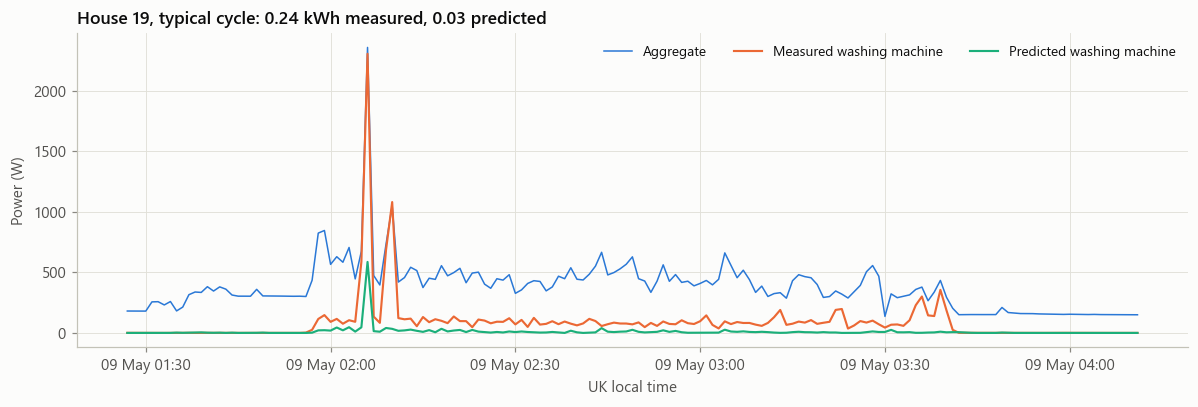

In [20]:
context = per_house.join(selected[["F1", "Recall", "R2", "Event_recall_original", "Energy_error_pct"]])
display(context.round(2))
for column in ("F1", "Recall", "Event_recall_original"):
    result = stats.spearmanr(context["median_heater_min"], context[column])
    print(f"Across homes, median heater minutes per event vs {column}: rho = {result.statistic:.2f}, p = {result.pvalue:.3f} (n = {len(context)})")

WORST = int(selected["Recall"].idxmin())
print(f"\nHome with the lowest recall: {WORST}")
worst_events = complete[complete["house"] == WORST]
display(worst_events.groupby("heater_band", observed=True).agg(events=("found", "size"), found_pct=("found", lambda s: 100 * s.mean()), true_kwh=("energy_kwh", "median"), pred_kwh=("pred_kwh", "median")).round(2))

minute_worst = prepare_clean_house(WORST)
table = predictions["selected"][predictions["selected"]["house"] == WORST].copy()
table["aggregate"] = minute_worst["aggregate"].reindex(table.index)
table["local_time"] = minute_worst["local_time"].reindex(table.index)
on_rows = table[(table["wm"] > cfg.ACTIVE_W) & table["eval_ok"]]
print(f"House {WORST}: threshold {thresholds['selected'][WORST]} W; median predicted power while ON {on_rows['pred'].median():.0f} W; median measured {on_rows['wm'].median():.0f} W; median aggregate while ON {on_rows['aggregate'].median():.0f} W")
typical = worst_events.iloc[(worst_events["energy_kwh"] - worst_events["energy_kwh"].median()).abs().argsort().iloc[0]]
window = table[(table.index >= typical["start"] - pd.Timedelta(minutes=30)) & (table.index <= typical["end"] + pd.Timedelta(minutes=30))]
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(window["local_time"], window["aggregate"], color=viz.BLUE, linewidth=1, label="Aggregate")
ax.plot(window["local_time"], window["wm"], color=viz.ORANGE, label="Measured washing machine")
ax.plot(window["local_time"], window["pred"], color=viz.AQUA, label="Predicted washing machine")
ax.set_title(f"House {WORST}, typical cycle: {typical['energy_kwh']:.2f} kWh measured, {typical['pred_kwh']:.2f} predicted")
ax.set_xlabel("UK local time"); ax.set_ylabel("Power (W)")
viz.format_time_axis(ax, "%d %b %H:%M")
ax.legend(loc="upper right", ncols=3)
fig.tight_layout()
viz.save(fig, "03_E_failure_missed_cycle")
plt.show()

**House 19 is explained by low heating. The same idea does not explain everything.**

**Within House 19 the evidence is strong.** Cycles with 6-15 minutes of heating are found 94% of the time (18 events), but those with 5 minutes or fewer only 24-26% (227 events). Its median cycle has just 2 heating minutes. In the chart, about 100 W of tumbling sits under a noisy 300-500 W background, so the model predicts about 15 W where the machine draws 97 W. Here the threshold rule beats the model (F1 0.30 against 0.23).

**Across homes the evidence is weak.** Median heating minutes against F1 gives rho = 0.48 (p = 0.13, n = 11), which is not significant.

**House 2 is a counterexample and remains unexplained.** Its recall is only 0.30, despite a typical 15 heating minutes per cycle. So low heating is one cause of misses, not the only one.

**Why this matters.** Low-temperature washing is often recommended to save energy. If House 19's cycles are low-temperature, which the data cannot confirm, then **the model would be worst on the homes already following that advice**, and it might not see a home switching to cooler washes. This must be tested before using it to measure such an intervention.

### Case 3: a stress test on homes excluded from training

Houses 1, 8, 9 and 18 have a washer-dryer as well as a washing machine, and were excluded from training. Their aggregate holds a second, similar load that the washing-machine channel does not include, so we expect false alarms to rise. The final model is applied to them with the median threshold from the LOHO folds.

In [21]:
model = saved["model"]
EXCLUDED = [1, 8, 9, 18]
rows = []
threshold = float(np.median(list(thresholds["selected"].values())))
for house in EXCLUDED:
    table, names = build_dataset([house])
    table = table.assign(pred=np.clip(model.predict(table[FEATURES].to_numpy(dtype="float32")), 0, None))
    result = evaluate(table, threshold)
    rows.append({"House": house, **result, "Abs_energy_error_pct": abs(result["Energy_error_pct"])})
    del table
    gc.collect()
excluded = pd.DataFrame(rows).set_index("House")
excluded.round(3).to_csv(cfg.METRICS / "excluded_homes_stress_test.csv")
print(f"Threshold used: {threshold} W")
display(excluded[["ON_pct", "MAE", "R2", "MAE_ON", "Precision", "Recall", "F1", "Energy_error_pct", "Events_true", "Events_pred", "Event_recall", "Event_precision", "Event_precision_original"]].round(2))
print("Mean, excluded homes: ", excluded[["R2", "Precision", "Recall", "F1", "Abs_energy_error_pct", "Event_precision", "Event_precision_original"]].mean().round(3).to_dict())
print("Mean, eligible homes: ", selected[["R2", "Precision", "Recall", "F1", "Abs_energy_error_pct", "Event_precision", "Event_precision_original"]].mean().round(3).to_dict())

Threshold used: 30.0 W


,ON_pct,MAE,R2,MAE_ON,Precision,Recall,F1,Energy_error_pct,Events_true,Events_pred,Event_recall,Event_precision,Event_precision_original
House,,,,,,,,,,,,,
1,1.83,17.63,0.20,439.59,0.18,0.73,0.29,16.83,379,2084,0.96,0.17,0.14
8,3.36,42.00,0.30,651.29,0.21,0.88,0.34,-0.79,375,3327,0.99,0.11,0.10
9,2.83,30.47,0.27,363.08,0.21,0.88,0.34,73.83,242,1951,1.00,0.12,0.11
18,1.22,14.72,0.32,240.05,0.13,0.84,0.22,178.43,138,1873,0.99,0.07,0.07


Mean, excluded homes:  {'R2': 0.272, 'Precision': 0.182, 'Recall': 0.833, 'F1': 0.297, 'Abs_energy_error_pct': 67.468, 'Event_precision': 0.117, 'Event_precision_original': 0.106}
Mean, eligible homes:  {'R2': 0.254, 'Precision': 0.301, 'Recall': 0.648, 'F1': 0.389, 'Abs_energy_error_pct': 21.346, 'Event_precision': 0.235, 'Event_precision_original': 0.228}


**Homes with a second washing load do worse on average, but the cause is not shown.** Compared with the 11 eligible homes:

- Precision falls from 0.30 to 0.18, and event precision from 0.235 to 0.117 (0.228 to 0.106 as originally reported).
- Mean absolute energy error rises from 21.3% to 67.5%, but the range is wide: -0.8% (House 8), +16.8% (House 1), +73.8% (House 9) and +178.4% (House 18), a median of 45.3%. House 6, with one machine, reaches +76%, so the error cannot be attributed to the second load alone.
- Recall rises from 0.65 to 0.83, because the model responds more often.
- R² does not fall (0.27 against 0.25), so R² alone would have hidden this problem.

**What this means for deployment.** A utility does not know which homes have a second machine, so real-world error could be well above the headline. **Limits:** only four homes, and this model trained on 11 homes rather than 10, with a shared threshold, so the comparison is approximate.

## 11. Which inputs matter?

Permutation importance: shuffle one feature and measure how much RMSE worsens. **Limits:** it uses the final model, on rows it trained on, from Houses 2, 5 and 6 only, with 2 repeats, and correlated features share credit. So it describes what the model relies on in those rows. It is not an accuracy result, and individual rankings should not be read closely.

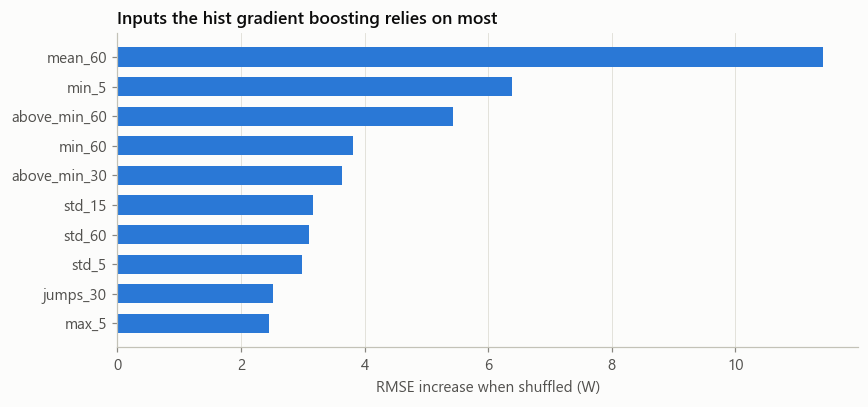

,feature,rmse_increase_w
28,mean_60,11.41
16,min_5,6.38
32,above_min_60,5.42
31,min_60,3.80
27,above_min_30,3.64
19,std_15,3.16
29,std_60,3.10
14,std_5,2.99
33,jumps_30,2.52
15,max_5,2.45


In [22]:
table, _ = build_dataset(HOUSES[:3])
sample = table.sample(120_000, random_state=cfg.RANDOM_SEED)
del table
gc.collect()
result = permutation_importance(model, sample[FEATURES].to_numpy(dtype="float32"), sample["wm"].to_numpy(dtype="float32"), n_repeats=2, random_state=cfg.RANDOM_SEED, scoring="neg_root_mean_squared_error", n_jobs=2)
importance = pd.DataFrame({"feature": FEATURES, "rmse_increase_w": result.importances_mean}).sort_values("rmse_increase_w", ascending=False)
importance.round(3).to_csv(cfg.METRICS / "feature_importance.csv", index=False)
top = importance.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(top["feature"], top["rmse_increase_w"], color=viz.BLUE, height=0.65)
ax.set_title(f"Inputs the {saved['method'].replace('_', ' ')} relies on most")
ax.set_xlabel("RMSE increase when shuffled (W)")
ax.grid(axis="y", visible=False)
fig.tight_layout()
viz.save(fig, "03_F_feature_importance")
plt.show()
display(importance.head(10).round(2))

**The model relies on recent context more than on the current reading.** The top input is the 60-minute mean, followed by the 5-minute minimum, and the height above the 60-minute low. These describe a sustained rise above a home's base load, and that fits the error analysis: a sustained 2 kW block is exactly what heating looks like, whichever appliance causes it. This describes the model's behaviour, and it does not show those inputs cause washing-machine use. Many features are correlated, so these three may stand in for others that carry the same information.

## Summary

| Question | Answer | Evidence |
|---|---|---|
| Is there real skill? | Yes | F1 0.389 against 0.062 by chance; all five leakage tests pass |
| Better than simple baselines? | Yes, on most measures | RMSE, ON-period MAE and F1 all improve significantly; event precision barely does |
| Can it find minutes the machine is on? | Weakly | Precision 0.30, recall 0.65 |
| Can it count cycles? | No | 1.06 to 5.0 times the true count depending on the rule; at about the right count, precision 0.49 and recall 0.48 |
| Is total energy right? | On average, partly by cancelling errors | 62% of predicted energy is in OFF minutes |
| Can it follow changes in a home? | **Strongest result, exploratory** | Weekly r = 0.61 (0.31-0.93), beating fixed share in all 11 homes and the threshold rule in 10, but the prediction moves only about 0.52 kWh per 1 kWh; detection in one home is not validated |
| Does it work on 15- or 30-minute data? | Not for power or cycle detail; weekly tracking degrades and is unvalidated | R² 0.03 and -0.07; weekly r 0.56 and 0.54 against 0.64 at 1 minute |

**Review of this section.** The regression formulation fits the brief, the features use no future data (tested), the test home is never used for training or selection, and baselines are meaningful. **Active-period errors remain large** (MAE 292 W), and this accuracy is not good enough for cycle-level feedback. Failure cases are partly understood: dishwashers and low heating are supported by evidence, while House 2 remains unexplained.

**Disclosure.** I saw Random Forest test scores before designing these failure analyses, the weekly analysis and the fixed-share baseline, so all of them are exploratory. No model setting was changed in response to them.